# 22. Train pooled calibration predictor with paired +δ / -δ priors, 3D rotation and tau (three sensors), Student distribution

This notebook extends the existing IMU + left-LiDAR experiment to an optional **right LiDAR**, retaining the same shared Transformer, calibration-wise pooler, shared MLP, loss, and model parameter shapes.

- Three calibration keys: `imu`, `lidar` (left), and `lidar_right`.
- Shared true-calibration augmentation is applied once before constructing the +δ/-δ pair.
- Both branches reuse the same physical measurements and opposite prior perturbations.
- The current configuration enables true-calibration rotation (30 deg) and tau (30 ms) augmentation, but disables frame randomization, noise, sampling-rate changes, generic prior perturbation and calibration events.
- Pair-prior perturbations use up to 5 deg rotation and 10 ms tau; translation is disabled.

The right LiDAR is enabled through `lidar_right_pose_filename` in `build_kaist_sequence_specs()`. All requested sequences must have that CSV. Old two-sensor model weights can initialize the shared model, but three-sensor performance must be validated and fine-tuned.


## 1. Imports and repository root


In [1]:
from pathlib import Path
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn.functional as F

ROOT = Path.cwd()
for candidate in (ROOT, *ROOT.parents):
    if (candidate / "src" / "obscalib").exists():
        ROOT = candidate
        break
else:
    raise FileNotFoundError("Could not locate the nn-obs-calib repository root containing src/obscalib.")

if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from kaist_dataset.dataset import KAISTCalibrationDataset, KAISTRigCalibration, build_kaist_sequence_specs, make_kaist_dataloader
from obscalib.augmentations.config import AugmentationConfig, CalibrationEventConfig, FrameRandomizationConfig, NoiseAugmentationConfig, PerturbationMagnitudeConfig, PriorPerturbationConfig, SamplingRateAugmentationConfig, TrueCalibrationAugmentationConfig
from obscalib.augmentations.pipeline import AugmentationPipeline
from obscalib.augmentations import PerturbationDistribution
from obscalib.augmentations.prior_perturbation import CalibrationPriorPerturber, apply_prior_perturbation
from obscalib.calibration.state import CalibrationState
from obscalib.calibration.update import CalibrationUpdater
from obscalib.config import CalibrationPoolerConfig, MLPConfig, PooledCalibrationHeadConfig, PooledCalibrationModelConfig, TransformerConfig, WindowingConfig
from obscalib.data.collation import collate_windows
from obscalib.data.device import window_batch_to
from obscalib.data.structures import WindowBatch
from obscalib.geometry.lie import se3_log
from obscalib.geometry.processing import GeometryProcessor
from obscalib.models.pooled_calibration_model import PooledCalibrationModel
from obscalib.pipeline.window_step import WindowStep
from obscalib.tokenization.tokenizer import Tokenizer
from obscalib.training.checkpoint import load_training_checkpoint, save_training_checkpoint
from obscalib.training.metrics_logger import MetricsLogger
import gc

print("Repository root:", ROOT)
print("PyTorch:", torch.__version__)


Repository root: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib
PyTorch: 2.7.1+cu126


## 2. Experiment parameters


In [ ]:
RUN_NAME = "kaist_pooled_calibration_paired_002.9_student"

RANDOM_SEED = 12345
TRAIN_PAIR_SEED = 23456
VALIDATION_PAIR_SEED = 34567
TEST_PAIR_SEED = 45678
VISUALIZATION_PAIR_SEED = 56789

DEVICE_NAME = "cuda"
DEVICE = torch.device("cuda" if DEVICE_NAME == "auto" and torch.cuda.is_available() else DEVICE_NAME)
MODEL_DTYPE = torch.float32

# Stable routing order for this rig. IDs are tuple positions only.
CALIBRATION_KEYS = ("imu", "lidar", "lidar_right")
CALIBRATION_CONTEXT_DIM = 7

WINDOW_DURATION_S = 5.0
WINDOW_STRIDE_S = 5.0
MAX_SAMPLES_PER_SENSOR = 700

BATCH_SIZE = 16
NUM_WORKERS = 0
DROP_LAST_TRAIN = True

NUM_EPOCHS = 200
LEARNING_RATE = 3e-4/16
WEIGHT_DECAY = 1e-4
GRADIENT_CLIP_NORM = 1.0
CHECKPOINT_EVERY_EPOCHS = 3
PRINT_EVERY_BATCHES = 500
LR_REDUCTION_FACTOR = 0.5
LR_PATIENCE_EPOCHS = 10

MEASUREMENT_DIM = 6
TOKEN_INPUT_DIM = MEASUREMENT_DIM + 2
D_MODEL = 128
N_HEADS = 8
NUM_TRANSFORMER_LAYERS = 12
DIM_FEEDFORWARD = 512
TRANSFORMER_DROPOUT = 0.
NUM_SUMMARY_TOKENS = 1

POOLER_N_HEADS = 8
POOLER_DROPOUT = 0.
MLP_HIDDEN_DIMS = (256, 128)
SHARED_FEATURE_DIM = 128
MLP_DROPOUT = 0.
HEAD_HIDDEN_DIMS = (128, 64)
HEAD_DROPOUT = 0.

CORRECTION_LOSS_TYPE = "mse"
ROTATION_LOSS_SCALE_RAD = np.deg2rad(5.0)
TRANSLATION_LOSS_SCALE_M = 0.05
# Characteristic temporal-calibration error scale [s].
# A delta_tau prediction error near 50 ms has normalized scale ~1.
TIME_OFFSET_LOSS_SCALE_S = 0.050

ROTATION_LOSS_WEIGHT = 2.0
TRANSLATION_LOSS_WEIGHT = 1.0
TIME_OFFSET_LOSS_WEIGHT = 1.0

# Pair difference is the new supervision term. The normal regression loss remains present on both branches.
PAIR_LOSS_WEIGHT = 0.1
TRUTH_ANCHOR_LOSS_WEIGHT = 1.0

# Keep event heads in the architecture but do not train them in this clean paired experiment.
CHANGE_EVENT_LOSS_WEIGHT = 0.0
CHANGE_TIME_LOSS_WEIGHT = 0.0

PAIR_ROTATION_MAX_RAD = np.deg2rad(5.0)
PAIR_TRANSLATION_MAX_M = 0.02
PAIR_TIME_OFFSET_MAX_S = 0.01

# Initialize the shared model weights from a two-sensor checkpoint; optimizer/scheduler stay fresh.
# Set to None if training from scratch. Do NOT reuse the old run directory for outputs.
RESUME_CHECKPOINT = ROOT / "runs" / "kaist_pooled_calibration_paired_002.8_3_sensors_3d_tau" / "best.pt"
# RESUME_CHECKPOINT = None

torch.manual_seed(RANDOM_SEED)
np.random.seed(RANDOM_SEED)

print("Device:", DEVICE)
print("Calibration order:", CALIBRATION_KEYS)
print("Correction loss:", CORRECTION_LOSS_TYPE)
print("Pair loss weight:", PAIR_LOSS_WEIGHT)
print("Pair prior bounds: rotation=5 deg, translation=disabled, time offset=10 ms")


Device: cuda
Calibration order: ('imu', 'lidar', 'lidar_right')
Correction loss: mse
Pair loss weight: 0.1
Pair prior bounds: rotation=5 deg, translation=disabled, time offset=10 ms


## 3. KAIST split, calibration, datasets, and loaders


In [45]:
KAIST_DATASET_ROOT = Path("/mnt/d/Downloads/MobRobLab/KAISTDataset")
LIDAR_POSE_ROOT = Path("/home/camel/Skoltech/phd_proposal/data/KAISTDataset")

TRAIN_NAMES = ["Urban08", "Urban12", "Urban13", "Urban14", "Urban15", "Urban16"]
VAL_NAMES = ["Urban26", "Urban28"]
TEST_NAMES = ["Urban38", "Urban39"]
ALL_SEQUENCE_NAMES = TRAIN_NAMES + VAL_NAMES + TEST_NAMES

if len(ALL_SEQUENCE_NAMES) != len(set(ALL_SEQUENCE_NAMES)):
    raise ValueError("Train, validation, and test sequence sets overlap.")

T_B_L = np.array([
    [-0.514066, -0.702201, -0.492595, -0.440699],
    [0.486485, -0.711672, 0.506809, 0.397052],
    [-0.706447, 0.0208933, 0.707457, 1.90953],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

# Right LiDAR -> body, in the same convention as T_B_L for the left LiDAR.
T_B_L_right = np.array([
    [-0.512152,  0.699241, -0.498761, -0.449885],
    [-0.494811, -0.714859, -0.494104, -0.416713],
    [-0.702041, -0.0062642, 0.712109,  1.91294],
    [ 0.0,       0.0,       0.0,       1.0],
], dtype=float)

T_I_B = np.array([
    [1.0, 0.0, 0.0, -0.07],
    [0.0, 1.0, 0.0, 0.0],
    [0.0, 0.0, 1.0, 1.7],
    [0.0, 0.0, 0.0, 1.0],
], dtype=float)

rig_calibration = KAISTRigCalibration(T_B_I=np.linalg.inv(T_I_B), T_B_L=T_B_L, tau_imu_s=0.0, tau_lidar_s=0.0, T_B_L_right=T_B_L_right, tau_lidar_right_s=0.0)
windowing_config = WindowingConfig(window_duration_s=WINDOW_DURATION_S, window_stride_s=WINDOW_STRIDE_S, max_samples_per_sensor=MAX_SAMPLES_PER_SENSOR)

print("train:", TRAIN_NAMES)
print("validation:", VAL_NAMES)
print("test:", TEST_NAMES)


train: ['Urban08', 'Urban12', 'Urban13', 'Urban14', 'Urban15', 'Urban16']
validation: ['Urban26', 'Urban28']
test: ['Urban38', 'Urban39']


In [4]:
all_specs = build_kaist_sequence_specs(sequence_names=ALL_SEQUENCE_NAMES, kaist_dataset_root=KAIST_DATASET_ROOT, lidar_pose_root=LIDAR_POSE_ROOT, lidar_right_pose_filename="lidar_map_poses_vlp_right.csv")

# The 3-sensor experiment must never silently fall back to 2 sensors.
for spec in all_specs:
    if spec.lidar_right_pose_csv is None or not spec.lidar_right_pose_csv.is_file():
        raise FileNotFoundError(f"Missing required right-LiDAR pose CSV for {spec.name}: {spec.lidar_right_pose_csv}")
spec_by_name = {spec.name: spec for spec in all_specs}

train_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TRAIN_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
val_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in VAL_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)
test_dataset = KAISTCalibrationDataset([spec_by_name[name] for name in TEST_NAMES], rig_calibration, windowing_config, measurement_dtype=torch.float32, source_timestamp_dtype=torch.float64, window_timestamp_dtype=torch.float32)

for split_name, dataset in (("train", train_dataset), ("validation", val_dataset), ("test", test_dataset)):
    if tuple(dataset.calibration_keys) != CALIBRATION_KEYS:
        raise AssertionError(f"{split_name} dataset has calibration keys {dataset.calibration_keys}, expected {CALIBRATION_KEYS}")

print(train_dataset.summary())
print()
print(val_dataset.summary())
print()
print(test_dataset.summary())


KAISTCalibrationDataset: 2006 windows from 6 sequences
approximate tensor storage: 44.0 MiB
  Urban08: windows=59, duration=297.8s, IMU=30800, LiDAR=2952, right LiDAR=2953
  Urban12: windows=473, duration=2478.6s, IMU=249198, LiDAR=23222, right LiDAR=23223
  Urban13: windows=223, duration=1446.5s, IMU=145492, LiDAR=10536, right LiDAR=10535
  Urban14: windows=286, duration=1737.0s, IMU=174681, LiDAR=13638, right LiDAR=13639
  Urban15: windows=184, duration=1034.3s, IMU=104795, LiDAR=9011, right LiDAR=9011
  Urban16: windows=781, duration=4458.1s, IMU=449215, LiDAR=37703, right LiDAR=37704

KAISTCalibrationDataset: 418 windows from 2 sequences
approximate tensor storage: 9.2 MiB
  Urban26: windows=94, duration=566.9s, IMU=58371, LiDAR=4553, right LiDAR=4551
  Urban28: windows=324, duration=1958.5s, IMU=197456, LiDAR=15651, right LiDAR=15658

KAISTCalibrationDataset: 699 windows from 2 sequences
approximate tensor storage: 15.4 MiB
  Urban38: windows=349, duration=2147.3s, IMU=216225, LiD

In [46]:
train_shuffle_generator = torch.Generator().manual_seed(RANDOM_SEED)
train_loader = make_kaist_dataloader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, drop_last=DROP_LAST_TRAIN, num_workers=NUM_WORKERS, generator=train_shuffle_generator)
val_loader = make_kaist_dataloader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)
test_loader = make_kaist_dataloader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, drop_last=False, num_workers=NUM_WORKERS)

print("train batches:", len(train_loader))
print("validation batches:", len(val_loader))
print("test batches:", len(test_loader))


train batches: 125
validation batches: 27
test batches: 44


## 4. Shared context augmentation and paired prior sampler


In [81]:
# Shared context augmentation is applied ONCE before the pair is split.
# Therefore +delta and -delta see exactly the same physical motion, frame randomization, targets, and streams.
#
# Effective settings:
#   frame randomization: OFF
#   true-calibration augmentation: ON (per-sensor rotation and time offset)
#   prior perturbation inside the generic pipeline: OFF (the +/- sampler is separate)
#   measurement noise: OFF
#   sampling-rate augmentation: OFF
#   calibration events: OFF
#
# The paired prior itself is sampled separately below.

context_augmentation_config = AugmentationConfig(
    sampling_rate=SamplingRateAugmentationConfig(enabled=False),
    frame_randomization=FrameRandomizationConfig(enabled=False),
    true_calibration=TrueCalibrationAugmentationConfig(
        enabled=True,
        probability=1.0,
        rotation_probability=1.0,
        translation_probability=0.0,
        time_offset_probability=1.0,
        rotation=PerturbationMagnitudeConfig(
            maximum=np.deg2rad(30.0),
        ),
        time_offset=PerturbationMagnitudeConfig(
            maximum=0.03,
        ),
    ),
    prior_perturbation=PriorPerturbationConfig(
        enabled=False,
        probability=1.0,
        rotation=PerturbationMagnitudeConfig(
            maximum=np.deg2rad(5.0),
        ),
        translation=PerturbationMagnitudeConfig(maximum=PAIR_TRANSLATION_MAX_M),
        time_offset=PerturbationMagnitudeConfig(maximum=PAIR_TIME_OFFSET_MAX_S),
        one_calibration_per_sample=True,
        one_rotation_axis_per_sample=True,
    ),
    calibration_event=CalibrationEventConfig(enabled=False),
    noise=NoiseAugmentationConfig(enabled=False),
)

pair_prior_config = PriorPerturbationConfig(
    enabled=True,
    probability=1.0,
    # rotation=None,
    rotation=PerturbationMagnitudeConfig(
        maximum=np.deg2rad(60.0),
        distribution=PerturbationDistribution.TRUNCATED_STUDENT_T,
        scale=np.deg2rad(30.0),
        degrees_of_freedom=3,
    ),
    translation=None,
    # time_offset=None,
    time_offset=PerturbationMagnitudeConfig(
        maximum=0.500,
        distribution=PerturbationDistribution.TRUNCATED_STUDENT_T,
        scale=0.250,
        degrees_of_freedom=3,
    ),
    one_calibration_per_sample=True,
    one_rotation_axis_per_sample=False,
    one_perturbation_type_per_sample=False,
)

context_augmentation_pipeline = AugmentationPipeline(context_augmentation_config)
pair_prior_perturber = CalibrationPriorPerturber(pair_prior_config)

print("Shared context augmentation:")
print(context_augmentation_config)
print()
print("Paired prior perturbation:")
print(pair_prior_config)


Shared context augmentation:
AugmentationConfig(sampling_rate=SamplingRateAugmentationConfig(enabled=False, minimum_imu_frequency_hz=None, minimum_lidar_frequency_hz=None, imu_probability=1.0, lidar_probability=1.0), frame_randomization=FrameRandomizationConfig(enabled=False), prior_perturbation=PriorPerturbationConfig(enabled=False, probability=1.0, probability_by_key={}, rotation=PerturbationMagnitudeConfig(maximum=0.08726646259971647, distribution=<PerturbationDistribution.UNIFORM: 'uniform'>, scale=None, degrees_of_freedom=3), translation=PerturbationMagnitudeConfig(maximum=0.02, distribution=<PerturbationDistribution.UNIFORM: 'uniform'>, scale=None, degrees_of_freedom=3), time_offset=PerturbationMagnitudeConfig(maximum=0.01, distribution=<PerturbationDistribution.UNIFORM: 'uniform'>, scale=None, degrees_of_freedom=3), one_calibration_per_sample=True, one_rotation_axis_per_sample=True, one_perturbation_type_per_sample=False), calibration_event=CalibrationEventConfig(enabled=False, 

## 5. Pooled model and complete window pipeline


In [82]:
model_config = PooledCalibrationModelConfig(
    transformer=TransformerConfig(input_dim=TOKEN_INPUT_DIM, d_model=D_MODEL, n_heads=N_HEADS, num_layers=NUM_TRANSFORMER_LAYERS, dim_feedforward=DIM_FEEDFORWARD, dropout=TRANSFORMER_DROPOUT, num_summary_tokens=NUM_SUMMARY_TOKENS, activation="gelu"),
    mlp=MLPConfig(hidden_dims=MLP_HIDDEN_DIMS, output_dim=SHARED_FEATURE_DIM, activation="gelu", dropout=MLP_DROPOUT),
    pooler=CalibrationPoolerConfig(
        n_heads=POOLER_N_HEADS,
        dropout=POOLER_DROPOUT,
        calibration_context_dim=0,           # CALIBRATION_CONTEXT_DIM
    ),

    head=PooledCalibrationHeadConfig(
        calibration_context_dim=0,
        hidden_dims=HEAD_HIDDEN_DIMS,
        activation="gelu",
        dropout=HEAD_DROPOUT,
    ),
)

geometry_processor = GeometryProcessor()
tokenizer = Tokenizer(measurement_dim=MEASUREMENT_DIM, calibration_keys=CALIBRATION_KEYS)
model = PooledCalibrationModel(model_config).to(device=DEVICE, dtype=MODEL_DTYPE)
calibration_updater = CalibrationUpdater()
window_step = WindowStep(geometry_processor=geometry_processor, tokenizer=tokenizer, model=model, calibration_updater=calibration_updater)

# if not getattr(model, "uses_calibration_context", False):
#     raise RuntimeError("This experiment requires the pooled model to use numeric calibration context.")

print(model)
print()
print("Parameters:", sum(parameter.numel() for parameter in model.parameters()))
print("Trainable parameters:", sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad))
print("Pooler calibration context dim:", model.pooler.calibration_context_dim)
print("Head calibration context dim:", model.head.config.calibration_context_dim)


PooledCalibrationModel(
  (transformer_encoder): SummaryTokenTransformerEncoder(
    (input_projection): Linear(in_features=8, out_features=128, bias=True)
    (encoder): TransformerEncoder(
      (layers): ModuleList(
        (0-11): 12 x TransformerEncoderLayer(
          (self_attn): MultiheadAttention(
            (out_proj): NonDynamicallyQuantizableLinear(in_features=128, out_features=128, bias=True)
          )
          (linear1): Linear(in_features=128, out_features=512, bias=True)
          (dropout): Dropout(p=0.0, inplace=False)
          (linear2): Linear(in_features=512, out_features=128, bias=True)
          (norm1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
          (norm2): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
          (dropout1): Dropout(p=0.0, inplace=False)
          (dropout2): Dropout(p=0.0, inplace=False)
        )
      )
    )
  )
  (pooler): CalibrationPooler(
    (attention): MultiheadAttention(
      (out_proj): NonDynamicallyQ

## 6. Paired-window construction helpers


In [83]:
def make_augmentation_generator(seed: int):
    return torch.Generator(device=DEVICE.type).manual_seed(seed)


def clone_window_with_calibration(window: WindowBatch, calibration):
    return WindowBatch(
        streams=dict(window.streams),
        current_calibration=calibration,
        metadata=dict(window.metadata),
        targets=None if window.targets is None else dict(window.targets),
        dataset_indices=window.dataset_indices,
    )


def make_paired_windows(base_window: WindowBatch, *, generator: torch.Generator, return_truth_window: bool = False):
    # Apply all shared physical/context augmentation once.
    context_result = context_augmentation_pipeline(base_window, generator=generator)
    context_window = context_result.augmented_window

    # Generic prior perturbation and calibration events are disabled here, so this is the exact
    # calibration associated with the shared physically augmented measurements.
    true_calibration = context_window.current_calibration

    # Sample one prior perturbation and construct symmetric +delta / -delta branches.
    _, delta_xi_by_key, delta_tau_by_key = pair_prior_perturber(true_calibration, generator=generator)

    positive_prior = apply_prior_perturbation(true_calibration, delta_xi_by_key, delta_tau_by_key)
    negative_prior = apply_prior_perturbation(true_calibration, {key: -value for key, value in delta_xi_by_key.items()}, {key: -value for key, value in delta_tau_by_key.items()})

    positive_window = clone_window_with_calibration(context_window, positive_prior)
    negative_window = clone_window_with_calibration(context_window, negative_prior)

    if return_truth_window:
        return positive_window, negative_window, context_window, delta_xi_by_key, delta_tau_by_key

    return positive_window, negative_window, delta_xi_by_key, delta_tau_by_key


def correction_target(window: WindowBatch, calibration_key: str):
    if window.targets is None:
        raise ValueError("Window has no calibration targets.")

    target = window.targets[calibration_key]
    current_state = window.current_calibration[calibration_key]

    if target.next_transform is None or target.next_time_offset is None:
        raise ValueError(f"Calibration target {calibration_key!r} does not contain the final calibration state.")

    target_delta_transform = target.next_transform @ torch.linalg.inv(current_state.transform)
    target_delta_xi = se3_log(target_delta_transform)
    target_delta_tau = target.next_time_offset - current_state.time_offset
    return target_delta_xi, target_delta_tau


## 7. Pair-construction semantic test


In [84]:
semantic_base_window = next(iter(train_loader))
semantic_base_window = window_batch_to(semantic_base_window, DEVICE, dtype=MODEL_DTYPE)
semantic_generator = make_augmentation_generator(TRAIN_PAIR_SEED + 1)
semantic_positive_window, semantic_negative_window, semantic_delta_xi, semantic_delta_tau = make_paired_windows(semantic_base_window, generator=semantic_generator)

for stream_key in semantic_positive_window.streams:
    torch.testing.assert_close(semantic_positive_window.streams[stream_key].values, semantic_negative_window.streams[stream_key].values)
    torch.testing.assert_close(semantic_positive_window.streams[stream_key].timestamps, semantic_negative_window.streams[stream_key].timestamps)

for calibration_key in CALIBRATION_KEYS:
    positive_target_xi, positive_target_tau = correction_target(semantic_positive_window, calibration_key)
    negative_target_xi, negative_target_tau = correction_target(semantic_negative_window, calibration_key)

    # For T_prior = Exp(+delta) @ T_true, the desired correction is -delta.
    torch.testing.assert_close(positive_target_xi, -semantic_delta_xi[calibration_key], atol=1e-5, rtol=1e-4)
    torch.testing.assert_close(negative_target_xi, semantic_delta_xi[calibration_key], atol=1e-5, rtol=1e-4)
    torch.testing.assert_close(positive_target_tau, -semantic_delta_tau[calibration_key], atol=1e-7, rtol=1e-6)
    torch.testing.assert_close(negative_target_tau, semantic_delta_tau[calibration_key], atol=1e-7, rtol=1e-6)

    torch.testing.assert_close(positive_target_xi + negative_target_xi, torch.zeros_like(positive_target_xi), atol=1e-5, rtol=1e-4)
    torch.testing.assert_close(positive_target_tau + negative_target_tau, torch.zeros_like(positive_target_tau), atol=1e-7, rtol=1e-6)

torch.cuda.empty_cache()

print("PAIR CONSTRUCTION CHECK: PASS")
print("The +delta and -delta branches share identical measurements and have opposite correction targets.")


PAIR CONSTRUCTION CHECK: PASS
The +delta and -delta branches share identical measurements and have opposite correction targets.


## 8. Routing and pooled-output sanity check


In [85]:
def run_pooled_sanity(window):
    with torch.inference_mode():
        result = window_step(window)
        tokens = result.tokens
        tokens.validate()

        if tokens.calibration_ids is None:
            raise RuntimeError("Pooled calibration requires calibration_ids.")

        if tuple(tokens.calibration_keys) != CALIBRATION_KEYS:
            raise RuntimeError(
                f"Tokenizer calibration order {tuple(tokens.calibration_keys)} "
                f"does not match requested {CALIBRATION_KEYS}."
            )

        if tuple(result.model_output.predictions) != CALIBRATION_KEYS:
            raise RuntimeError(
                f"Prediction key order {tuple(result.model_output.predictions)} "
                f"does not match {CALIBRATION_KEYS}."
            )

        summary = {
            "token_shape": tuple(tokens.x.shape),
            "shared_feature_shape": (
                None
                if result.model_output.shared_features is None
                else tuple(result.model_output.shared_features.shape)
            ),
        }

        # Move only the tiny outputs needed for comparison to CPU.
        predictions = {
            calibration_key: {
                "delta_xi": prediction.delta_xi.detach().cpu(),
                "delta_tau": prediction.delta_tau.detach().cpu(),
            }
            for calibration_key, prediction in result.model_output.predictions.items()
        }

    return summary, predictions


previous_training_mode = model.training
model.eval()

positive_summary, positive_predictions = run_pooled_sanity(
    semantic_positive_window
)

negative_summary, negative_predictions = run_pooled_sanity(
    semantic_negative_window
)

model.train(previous_training_mode)


for result_name, summary in (
    ("positive", positive_summary),
    ("negative", negative_summary),
):
    print(result_name)
    print("  token shape:", summary["token_shape"])
    print(
        "  pooled/shared feature shape:",
        summary["shared_feature_shape"],
    )


print()

for calibration_key in CALIBRATION_KEYS:
    positive_prediction = positive_predictions[calibration_key]
    negative_prediction = negative_predictions[calibration_key]

    print(calibration_key)
    print(
        "  delta_xi:",
        tuple(positive_prediction["delta_xi"].shape),
    )
    print(
        "  delta_tau:",
        tuple(positive_prediction["delta_tau"].shape),
    )
    print(
        "  initial prediction separation xi:",
        float(
            torch.linalg.vector_norm(
                positive_prediction["delta_xi"]
                - negative_prediction["delta_xi"],
                dim=-1,
            ).mean()
        ),
    )


# These are CPU-only now.
del positive_predictions
del negative_predictions
del positive_summary
del negative_summary
del positive_prediction
del negative_prediction

torch.cuda.empty_cache()

positive
  token shape: (16, 1098, 8)
  pooled/shared feature shape: (16, 3, 128)
negative
  token shape: (16, 1098, 8)
  pooled/shared feature shape: (16, 3, 128)

imu
  delta_xi: (16, 6)
  delta_tau: (16, 1)
  initial prediction separation xi: 2.7594463972491212e-05
lidar
  delta_xi: (16, 6)
  delta_tau: (16, 1)
  initial prediction separation xi: 3.092727274633944e-05
lidar_right
  delta_xi: (16, 6)
  delta_tau: (16, 1)
  initial prediction separation xi: 2.9272050596773624e-05


## 9. Regression and pair-difference losses


In [86]:
def correction_regression_loss(prediction, target):
    if CORRECTION_LOSS_TYPE == "mse":
        return F.mse_loss(prediction, target)
    if CORRECTION_LOSS_TYPE == "smooth_l1":
        return F.smooth_l1_loss(prediction, target, beta=1.0)
    if CORRECTION_LOSS_TYPE == "l1":
        return F.l1_loss(prediction, target)
    raise ValueError(f"Unknown CORRECTION_LOSS_TYPE={CORRECTION_LOSS_TYPE!r}.")


def compute_training_loss(window, model_output):
    total_loss = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)
    metrics = {}
    num_calibrations = 0

    for calibration_key, prediction in model_output.predictions.items():
        target_delta_xi, target_delta_tau = correction_target(window, calibration_key)

        rotation_loss = correction_regression_loss(prediction.delta_xi[:, :3] / ROTATION_LOSS_SCALE_RAD, target_delta_xi[:, :3] / ROTATION_LOSS_SCALE_RAD)
        translation_loss = correction_regression_loss(prediction.delta_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M, target_delta_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M)
        time_offset_loss = correction_regression_loss(prediction.delta_tau / TIME_OFFSET_LOSS_SCALE_S, target_delta_tau / TIME_OFFSET_LOSS_SCALE_S)

        calibration_loss = ROTATION_LOSS_WEIGHT * rotation_loss + TRANSLATION_LOSS_WEIGHT * translation_loss + TIME_OFFSET_LOSS_WEIGHT * time_offset_loss
        total_loss = total_loss + calibration_loss
        num_calibrations += 1

        rotation_error_rad = torch.linalg.vector_norm(prediction.delta_xi[:, :3] - target_delta_xi[:, :3], dim=-1)
        translation_error_m = torch.linalg.vector_norm(prediction.delta_xi[:, 3:] - target_delta_xi[:, 3:], dim=-1)
        time_offset_error_s = torch.abs(prediction.delta_tau[:, 0] - target_delta_tau[:, 0])

        metrics[f"{calibration_key}/rotation_error_deg"] = torch.rad2deg(rotation_error_rad).mean().item()
        metrics[f"{calibration_key}/translation_error_cm"] = (100.0 * translation_error_m).mean().item()
        metrics[f"{calibration_key}/time_offset_error_ms"] = (1000.0 * time_offset_error_s).mean().item()
        metrics[f"{calibration_key}/loss_rotation"] = rotation_loss.detach().item()
        metrics[f"{calibration_key}/loss_translation"] = translation_loss.detach().item()
        metrics[f"{calibration_key}/loss_time_offset"] = time_offset_loss.detach().item()

    if num_calibrations == 0:
        raise ValueError("Model produced no calibration predictions.")

    total_loss = total_loss / num_calibrations
    metrics["loss_total"] = total_loss.detach().item()
    return total_loss, metrics


def compute_pair_difference_loss(positive_window, positive_output, negative_window, negative_output):
    total_pair_loss = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)
    metrics = {}
    num_calibrations = 0

    for calibration_key in CALIBRATION_KEYS:
        positive_prediction = positive_output.predictions[calibration_key]
        negative_prediction = negative_output.predictions[calibration_key]

        positive_target_xi, positive_target_tau = correction_target(positive_window, calibration_key)
        negative_target_xi, negative_target_tau = correction_target(negative_window, calibration_key)

        predicted_difference_xi = positive_prediction.delta_xi - negative_prediction.delta_xi
        target_difference_xi = positive_target_xi - negative_target_xi
        predicted_difference_tau = positive_prediction.delta_tau - negative_prediction.delta_tau
        target_difference_tau = positive_target_tau - negative_target_tau

        active_rotation_mask = torch.abs(target_difference_xi[:, :3]) > 1e-10

        if torch.any(active_rotation_mask):
            pair_rotation_loss = correction_regression_loss(predicted_difference_xi[:, :3][active_rotation_mask] / ROTATION_LOSS_SCALE_RAD, target_difference_xi[:, :3][active_rotation_mask] / ROTATION_LOSS_SCALE_RAD)
        else:
            pair_rotation_loss = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)

        pair_translation_loss = correction_regression_loss(predicted_difference_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M, target_difference_xi[:, 3:] / TRANSLATION_LOSS_SCALE_M)
        pair_time_offset_loss = correction_regression_loss(predicted_difference_tau / TIME_OFFSET_LOSS_SCALE_S, target_difference_tau / TIME_OFFSET_LOSS_SCALE_S)

        calibration_pair_loss = ROTATION_LOSS_WEIGHT * pair_rotation_loss + TRANSLATION_LOSS_WEIGHT * pair_translation_loss + TIME_OFFSET_LOSS_WEIGHT * pair_time_offset_loss
        total_pair_loss = total_pair_loss + calibration_pair_loss
        num_calibrations += 1

        metrics[f"{calibration_key}/pair_loss_rotation"] = pair_rotation_loss.detach().item()
        metrics[f"{calibration_key}/pair_loss_translation"] = pair_translation_loss.detach().item()
        metrics[f"{calibration_key}/pair_loss_time_offset"] = pair_time_offset_loss.detach().item()

    if num_calibrations == 0:
        raise ValueError("Model produced no calibration predictions.")

    total_pair_loss = total_pair_loss / num_calibrations
    metrics["loss_pair"] = total_pair_loss.detach().item()

    return total_pair_loss, metrics


def compute_paired_objective(positive_window, positive_output, negative_window, negative_output, truth_window=None, truth_output=None):
    positive_loss, positive_metrics = compute_training_loss(positive_window, positive_output)
    negative_loss, negative_metrics = compute_training_loss(negative_window, negative_output)
    pair_loss, pair_metrics = compute_pair_difference_loss(positive_window, positive_output, negative_window, negative_output)

    regular_loss = 0.5 * (positive_loss + negative_loss)

    if truth_window is not None or truth_output is not None:
        if truth_window is None or truth_output is None:
            raise ValueError("truth_window and truth_output must either both be provided or both be None.")

        truth_loss, truth_metrics = compute_training_loss(truth_window, truth_output)
    else:
        truth_loss = torch.zeros((), dtype=MODEL_DTYPE, device=DEVICE)
        truth_metrics = {}

    total_loss = regular_loss + PAIR_LOSS_WEIGHT * pair_loss + TRUTH_ANCHOR_LOSS_WEIGHT * truth_loss

    metrics = {
        "loss_total": total_loss.detach().item(),
        "loss_regular": regular_loss.detach().item(),
        "loss_pair": pair_loss.detach().item(),
        "loss_truth": truth_loss.detach().item(),
    }

    for key in positive_metrics:
        if key == "loss_total":
            continue

        metrics[f"positive/{key}"] = positive_metrics[key]
        metrics[f"negative/{key}"] = negative_metrics[key]
        metrics[f"mean/{key}"] = 0.5 * (positive_metrics[key] + negative_metrics[key])

    for key, value in truth_metrics.items():
        if key != "loss_total":
            metrics[f"truth/{key}"] = value

    metrics.update({f"pair/{key}": value for key, value in pair_metrics.items()})

    return total_loss, metrics


optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode="min", factor=LR_REDUCTION_FACTOR, patience=LR_PATIENCE_EPOCHS)


In [87]:
from obscalib.augmentations.config import PerturbationMagnitudeConfig
from obscalib.augmentations.prior_perturbation import apply_prior_perturbation
from obscalib.augmentations.sampling import sample_signed_scalar_perturbation
from obscalib.geometry.lie import se3_log


DIRECTIONAL_CALIBRATION_KEY = "imu"
DIRECTIONAL_ROTATION_INDEX = 1  # phi_y
DIRECTIONAL_ROTATION_MAX_RAD = np.deg2rad(5.0)
DIRECTIONAL_PAIR_LOSS_WEIGHT = 10.0

directional_rotation_config = PerturbationMagnitudeConfig(
    maximum=DIRECTIONAL_ROTATION_MAX_RAD,
)


def make_directional_paired_windows(base_window: WindowBatch, *, generator: torch.Generator):
    """Development-only +/- pair with a single rotational prior-error coordinate."""

    # Keep the full shared physical augmentation, especially varying true calibration.
    context_result = context_augmentation_pipeline(base_window, generator=generator)
    context_window = context_result.augmented_window
    true_calibration = context_window.current_calibration

    delta_xi_by_key = {}
    delta_tau_by_key = {}

    for calibration_key, state in true_calibration.items():
        batch_size = state.transform.shape[0]
        device = state.transform.device
        dtype = state.transform.dtype

        delta_xi_by_key[calibration_key] = torch.zeros(batch_size, 6, device=device, dtype=dtype)
        delta_tau_by_key[calibration_key] = torch.zeros(batch_size, 1, device=device, dtype=dtype)

    selected_state = true_calibration[DIRECTIONAL_CALIBRATION_KEY]

    delta_rotation = sample_signed_scalar_perturbation(
        config=directional_rotation_config,
        batch_size=selected_state.transform.shape[0],
        device=selected_state.transform.device,
        dtype=selected_state.transform.dtype,
        generator=generator,
    )

    delta_xi_by_key[DIRECTIONAL_CALIBRATION_KEY][:, DIRECTIONAL_ROTATION_INDEX] = delta_rotation[:, 0]

    positive_prior = apply_prior_perturbation(
        true_calibration,
        delta_xi_by_key,
        delta_tau_by_key,
    )

    negative_prior = apply_prior_perturbation(
        true_calibration,
        {key: -value for key, value in delta_xi_by_key.items()},
        {key: -value for key, value in delta_tau_by_key.items()},
    )

    positive_window = clone_window_with_calibration(context_window, positive_prior)
    negative_window = clone_window_with_calibration(context_window, negative_prior)

    return positive_window, negative_window, delta_xi_by_key, delta_tau_by_key

In [88]:
def _directional_rotation_target(window: WindowBatch) -> torch.Tensor:
    current_state = window.current_calibration[DIRECTIONAL_CALIBRATION_KEY]
    target = window.targets[DIRECTIONAL_CALIBRATION_KEY]

    if target.next_transform is None:
        raise ValueError("Directional diagnostic requires next_transform supervision.")

    target_delta_transform = target.next_transform @ torch.linalg.inv(current_state.transform)
    target_delta_xi = se3_log(target_delta_transform)

    return target_delta_xi[:, DIRECTIONAL_ROTATION_INDEX]


def compute_directional_paired_objective(
    positive_window: WindowBatch,
    positive_output,
    negative_window: WindowBatch,
    negative_output,
):
    """Regular + strongly weighted pair loss for one selected rotation coordinate only."""

    positive_prediction = positive_output.predictions[DIRECTIONAL_CALIBRATION_KEY].delta_xi[:, DIRECTIONAL_ROTATION_INDEX]
    negative_prediction = negative_output.predictions[DIRECTIONAL_CALIBRATION_KEY].delta_xi[:, DIRECTIONAL_ROTATION_INDEX]

    positive_target = _directional_rotation_target(positive_window)
    negative_target = _directional_rotation_target(negative_window)

    positive_prediction_normalized = positive_prediction / ROTATION_LOSS_SCALE_RAD
    negative_prediction_normalized = negative_prediction / ROTATION_LOSS_SCALE_RAD
    positive_target_normalized = positive_target / ROTATION_LOSS_SCALE_RAD
    negative_target_normalized = negative_target / ROTATION_LOSS_SCALE_RAD

    loss_regular = 0.5 * (
        F.mse_loss(positive_prediction_normalized, positive_target_normalized)
        + F.mse_loss(negative_prediction_normalized, negative_target_normalized)
    )

    loss_pair = F.mse_loss(
        positive_prediction_normalized - negative_prediction_normalized,
        positive_target_normalized - negative_target_normalized,
    )

    loss_total = loss_regular + DIRECTIONAL_PAIR_LOSS_WEIGHT * loss_pair

    metrics = {
        "loss_total": loss_total.detach(),
        "loss_regular": loss_regular.detach(),
        "loss_pair": loss_pair.detach(),
    }

    return loss_total, metrics

In [89]:
from obscalib.augmentations.sampling import sample_isotropic_perturbation


SINGLE_SENSOR_3D_CALIBRATION_KEY = "lidar"

single_sensor_rotation_config = PerturbationMagnitudeConfig(
    maximum=np.deg2rad(5.0),
)


def make_single_sensor_3d_paired_windows(base_window: WindowBatch, *, generator: torch.Generator):
    """Development diagnostic: vary true calibration normally but perturb one sensor prior in full 3D rotation only."""

    context_result = context_augmentation_pipeline(base_window, generator=generator)
    context_window = context_result.augmented_window
    true_calibration = context_window.current_calibration

    delta_xi_by_key = {}
    delta_tau_by_key = {}

    for calibration_key, state in true_calibration.items():
        batch_size = state.transform.shape[0]

        delta_xi_by_key[calibration_key] = torch.zeros(
            batch_size,
            6,
            device=state.transform.device,
            dtype=state.transform.dtype,
        )

        delta_tau_by_key[calibration_key] = torch.zeros(
            batch_size,
            1,
            device=state.transform.device,
            dtype=state.transform.dtype,
        )

    selected_state = true_calibration[SINGLE_SENSOR_3D_CALIBRATION_KEY]

    delta_phi = sample_isotropic_perturbation(
        config=single_sensor_rotation_config,
        batch_size=selected_state.transform.shape[0],
        dimension=3,
        device=selected_state.transform.device,
        dtype=selected_state.transform.dtype,
        generator=generator,
    )

    delta_xi_by_key[SINGLE_SENSOR_3D_CALIBRATION_KEY][:, :3] = delta_phi

    positive_prior = apply_prior_perturbation(
        true_calibration,
        delta_xi_by_key,
        delta_tau_by_key,
    )

    negative_prior = apply_prior_perturbation(
        true_calibration,
        {key: -value for key, value in delta_xi_by_key.items()},
        {key: -value for key, value in delta_tau_by_key.items()},
    )

    positive_window = clone_window_with_calibration(
        context_window,
        positive_prior,
    )

    negative_window = clone_window_with_calibration(
        context_window,
        negative_prior,
    )

    return (
        positive_window,
        negative_window,
        delta_xi_by_key,
        delta_tau_by_key,
    )

## 10. Metric helpers


In [90]:
def accumulate_metrics(metric_sums, metrics, batch_size):
    for key, value in metrics.items():
        metric_sums[key] = metric_sums.get(key, 0.0) + float(value) * batch_size


def normalize_metrics(metric_sums, num_samples):
    if num_samples <= 0:
        raise ValueError("num_samples must be positive.")
    return {key: value / num_samples for key, value in metric_sums.items()}


## 11. One-batch paired gradient smoke test


In [91]:
from obscalib.calibration.context import calibration_state_to_context

context_test_base_window = next(iter(train_loader))
context_test_base_window = window_batch_to(
    context_test_base_window,
    DEVICE,
    dtype=MODEL_DTYPE,
)

context_test_generator = make_augmentation_generator(
    TRAIN_PAIR_SEED + 123
)

(
    context_test_positive_window,
    context_test_negative_window,
    _,
    _,
) = make_paired_windows(
    context_test_base_window,
    generator=context_test_generator,
)

positive_context = {
    calibration_key: calibration_state_to_context(state)
    for calibration_key, state
    in context_test_positive_window.current_calibration.items()
}

negative_context = {
    calibration_key: calibration_state_to_context(state)
    for calibration_key, state
    in context_test_negative_window.current_calibration.items()
}

model.eval()

with torch.inference_mode():
    # Generate tokens once.
    positive_step = window_step(
        context_test_positive_window
    )

    fixed_tokens = positive_step.tokens

    # Same exact measurement tokens, different numeric priors.
    output_positive_context = model(
        fixed_tokens,
        positive_context,
    )

    output_negative_context = model(
        fixed_tokens,
        negative_context,
    )

print("=" * 90)
print("CALIBRATION CONTEXT PATH CHECK")
print("=" * 90)

for calibration_key in CALIBRATION_KEYS:
    positive_prediction = (
        output_positive_context
        .predictions[calibration_key]
    )

    negative_prediction = (
        output_negative_context
        .predictions[calibration_key]
    )

    xi_separation = torch.linalg.vector_norm(
        positive_prediction.delta_xi
        - negative_prediction.delta_xi,
        dim=-1,
    ).mean()

    tau_separation = torch.abs(
        positive_prediction.delta_tau
        - negative_prediction.delta_tau
    ).mean()

    print(calibration_key)
    print(
        "  xi separation:",
        float(xi_separation.cpu()),
    )
    print(
        "  tau separation:",
        float(tau_separation.cpu()),
    )

del positive_step
del output_positive_context
del output_negative_context
del fixed_tokens
del context_test_base_window
del context_test_positive_window
del context_test_negative_window

torch.cuda.empty_cache()

CALIBRATION CONTEXT PATH CHECK
imu
  xi separation: 0.0
  tau separation: 0.0
lidar
  xi separation: 0.0
  tau separation: 0.0
lidar_right
  xi separation: 0.0
  tau separation: 0.0


In [92]:
# Paired gradient smoke test.
#
# Use a deliberately tiny batch. This test only verifies that the paired
# objective produces finite, nonzero gradients through the model. It does
# not need to reproduce the memory footprint of full training.

SMOKE_BATCH_SIZE = 2

previous_training_mode = model.training

try:
    torch.cuda.empty_cache()

    ##################################################
    # Tiny smoke batch
    ##################################################

    smoke_indices = np.linspace(
        0,
        len(train_dataset) - 1,
        SMOKE_BATCH_SIZE,
        dtype=int,
    )

    smoke_base_window = collate_windows(
        [
            train_dataset[int(index)]
            for index in smoke_indices
        ]
    )

    smoke_base_window = window_batch_to(
        smoke_base_window,
        DEVICE,
        dtype=MODEL_DTYPE,
    )

    smoke_generator = make_augmentation_generator(
        TRAIN_PAIR_SEED + 2
    )

    (
        smoke_positive_window,
        smoke_negative_window,
        _,
        _,
    ) = make_paired_windows(
        smoke_base_window,
        generator=smoke_generator,
    )

    ##################################################
    # Forward + backward
    ##################################################

    model.train()
    optimizer.zero_grad(set_to_none=True)

    smoke_positive_result = window_step(
        smoke_positive_window
    )

    smoke_negative_result = window_step(
        smoke_negative_window
    )

    smoke_loss, smoke_metrics = compute_paired_objective(
        smoke_positive_window,
        smoke_positive_result.model_output,
        smoke_negative_window,
        smoke_negative_result.model_output,
    )

    smoke_loss.backward()

    ##################################################
    # Gradient diagnostic
    ##################################################

    gradient_norm_squared = 0.0
    num_parameters_with_gradient = 0

    for parameter in model.parameters():
        if parameter.grad is None:
            continue

        parameter_gradient_norm = float(
            torch.linalg.vector_norm(
                parameter.grad.detach()
            ).cpu()
        )

        gradient_norm_squared += (
            parameter_gradient_norm ** 2
        )

        num_parameters_with_gradient += 1

    gradient_norm = (
        gradient_norm_squared ** 0.5
    )

    smoke_loss_value = float(
        smoke_loss.detach().cpu()
    )

    print(
        "Paired smoke loss:",
        smoke_loss_value,
    )

    print(
        "  regular:",
        smoke_metrics["loss_regular"],
    )

    print(
        "  pair:",
        smoke_metrics["loss_pair"],
    )

    print(
        "Gradient norm:",
        gradient_norm,
    )

    print(
        "Parameters with gradients:",
        num_parameters_with_gradient,
    )

    if not np.isfinite(smoke_loss_value):
        raise RuntimeError(
            "Paired smoke loss is not finite."
        )

    if (
        not np.isfinite(gradient_norm)
        or gradient_norm <= 0.0
    ):
        raise RuntimeError(
            "Pooled model did not receive a finite "
            "nonzero paired-training gradient."
        )

    print(
        "PAIRED GRADIENT SMOKE CHECK: PASS"
    )

finally:
    ##################################################
    # Remove gradients and all large graph references
    ##################################################

    optimizer.zero_grad(
        set_to_none=True
    )

    model.train(
        previous_training_mode
    )

    for variable_name in (
        "smoke_positive_result",
        "smoke_negative_result",
        "smoke_loss",
        "smoke_metrics",
        "smoke_positive_window",
        "smoke_negative_window",
        "smoke_base_window",
        "smoke_generator",
    ):
        if variable_name in globals():
            del globals()[variable_name]

    torch.cuda.empty_cache()

Paired smoke loss: 36.02984619140625
  regular: 27.897212982177734
  pair: 81.32630920410156
Gradient norm: 99.42935775856964
Parameters with gradients: 166
PAIRED GRADIENT SMOKE CHECK: PASS


## 12. Fixed paired small-batch overfit test

This is the direct counterpart of the successful fixed overfit test from notebook 16. It verifies that the new pair objective itself is trainable. Both branches and their perturbations are frozen here.


In [93]:
# FIXED_PAIR_OVERFIT_NUM_WINDOWS = min(BATCH_SIZE, 16)
# FIXED_PAIR_OVERFIT_NUM_STEPS = 400
# FIXED_PAIR_OVERFIT_PRINT_EVERY = 25
# FIXED_PAIR_OVERFIT_SEED = TRAIN_PAIR_SEED + 100000

# fixed_pair_indices = np.linspace(0, len(train_dataset) - 1, FIXED_PAIR_OVERFIT_NUM_WINDOWS, dtype=int)
# fixed_pair_base_window = collate_windows([train_dataset[int(index)] for index in fixed_pair_indices])
# fixed_pair_base_window = window_batch_to(fixed_pair_base_window, DEVICE, dtype=MODEL_DTYPE)

# fixed_pair_generator = make_augmentation_generator(FIXED_PAIR_OVERFIT_SEED)
# fixed_pair_positive_window, fixed_pair_negative_window, _, _ = make_paired_windows(fixed_pair_base_window, generator=fixed_pair_generator)

# fixed_pair_model_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
# fixed_pair_previous_training_mode = model.training
# fixed_pair_optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
# fixed_pair_history = []

# print("=" * 110)
# print("FIXED PAIRED SMALL-BATCH OVERFIT DIAGNOSTIC")
# print("=" * 110)
# torch.cuda.empty_cache()
# model.train()

# for step in range(FIXED_PAIR_OVERFIT_NUM_STEPS + 1):
#     fixed_pair_optimizer.zero_grad(set_to_none=True)

#     positive_result = window_step(fixed_pair_positive_window)
#     negative_result = window_step(fixed_pair_negative_window)
#     loss, metrics = compute_paired_objective(fixed_pair_positive_window, positive_result.model_output, fixed_pair_negative_window, negative_result.model_output)
#     fixed_pair_history.append(float(loss.detach()))

#     if step == 0 or step % FIXED_PAIR_OVERFIT_PRINT_EVERY == 0 or step == FIXED_PAIR_OVERFIT_NUM_STEPS:
#         print(f"step {step:4d}/{FIXED_PAIR_OVERFIT_NUM_STEPS} total={loss.item():9.6f} regular={metrics['loss_regular']:9.6f} pair={metrics['loss_pair']:9.6f}")

#     if step == FIXED_PAIR_OVERFIT_NUM_STEPS:
#         break

#     loss.backward()
#     if GRADIENT_CLIP_NORM is not None:
#         torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
#     fixed_pair_optimizer.step()

# fixed_pair_fraction_remaining = fixed_pair_history[-1] / fixed_pair_history[0]

# print()
# print(f"Initial loss: {fixed_pair_history[0]:.6f}")
# print(f"Final loss:   {fixed_pair_history[-1]:.6f}")
# print(f"Remaining:    {100.0 * fixed_pair_fraction_remaining:.2f}% of initial loss")
# print("FIXED PAIRED OVERFIT CHECK:", "PASS" if fixed_pair_fraction_remaining < 0.10 else "FAIL/WARNING")

# plt.figure(figsize=(10, 4))
# plt.plot(fixed_pair_history)
# plt.yscale("log")
# plt.xlabel("optimization step")
# plt.ylabel("paired objective")
# plt.title("Fixed paired small-batch overfit diagnostic")
# plt.grid(True)
# plt.show()

# model.load_state_dict(fixed_pair_model_state)
# model.train(fixed_pair_previous_training_mode)
# model.zero_grad(set_to_none=True)

# del fixed_pair_optimizer
# del fixed_pair_model_state
# torch.cuda.empty_cache()

## 13. Stochastic paired small-set learnability gate

The physical windows stay fixed, but shared frame randomization and the paired prior perturbation are resampled every step. The model is evaluated on one fixed unseen paired draw. This is the decisive small test before the full run.

The full 200-epoch run is enabled automatically only if the fixed-evaluation paired objective falls below 50% of its initial value.


Stochastic diagnostic initialized from: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.8_3_sensors_3d_tau/best.pt
STOCHASTIC PAIRED SMALL-SET LEARNABILITY DIAGNOSTIC
fixed physical windows: 16
optimization steps: 500
DIRECTIONAL = False
fresh shared frame randomization and fresh +/- prior pair sampled at every training step

initial fixed-eval total=14.426538 regular=7.215878 pair=72.106590
initial tau pair: imu=12.639380, lidar=2.251639, lidar_right=14.163092 | mean=9.684704
initial tau error: imu=34.5191 ms, lidar=16.7866 ms, lidar_right=52.8541 ms

step    1/500 train=13.018816 eval_total=14.230419 eval_regular= 7.096045 eval_pair=71.343735 | tau_pair imu=12.112322, lidar=2.254334, lidar_right=13.800170 | tau_err imu=33.927 ms, lidar=16.458 ms, lidar_right=51.231 ms
step   25/500 train=10.614424 eval_total=11.699785 eval_regular= 5.612164 eval_pair=60.876213 | tau_pair imu=5.971459, lidar=1.086495, lidar_right=9.125772 | tau_err imu=25

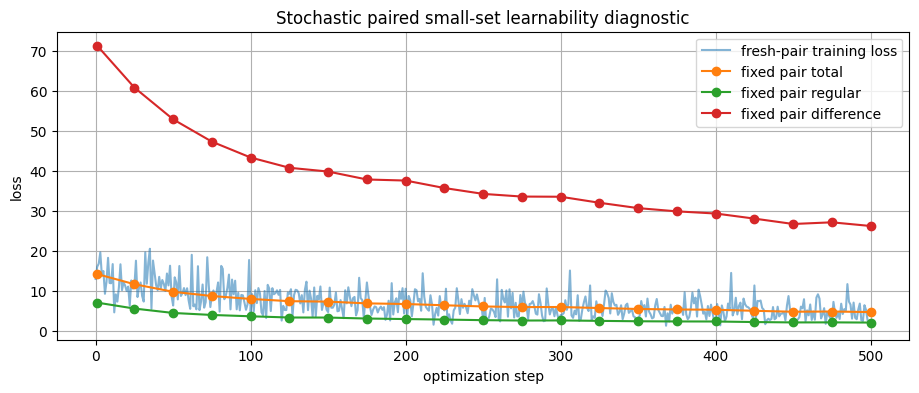

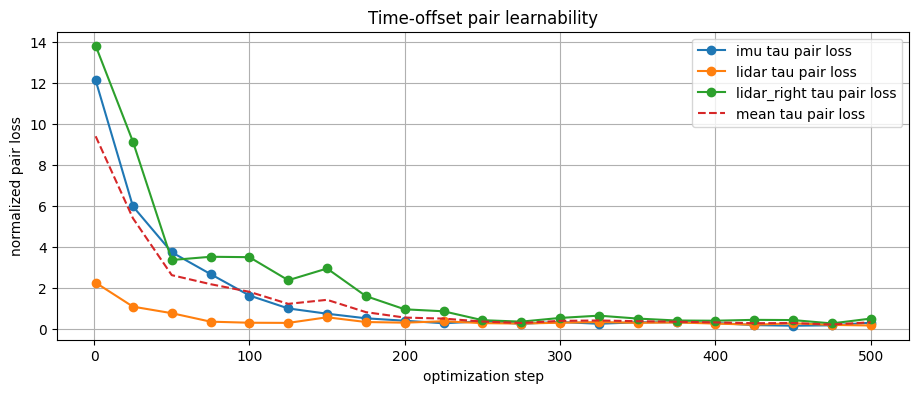

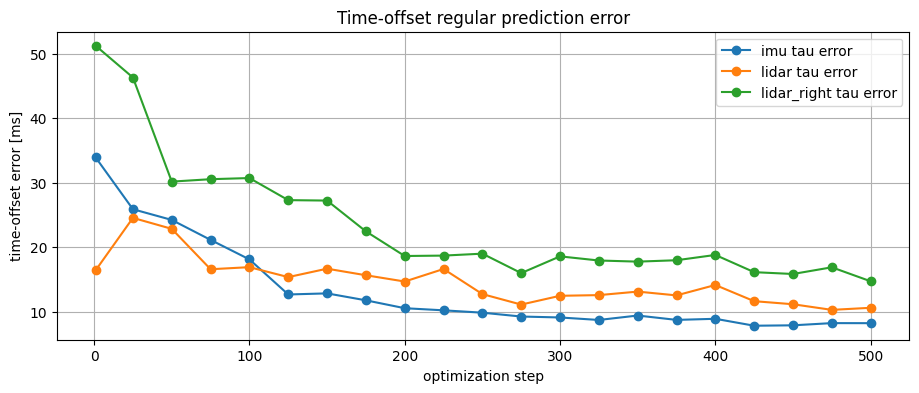


RUN_FULL_TRAINING = True


In [94]:
STOCHASTIC_PAIR_NUM_WINDOWS = min(BATCH_SIZE, 16)
STOCHASTIC_PAIR_NUM_STEPS = 500
STOCHASTIC_PAIR_PRINT_EVERY = 25
STOCHASTIC_PAIR_TRAIN_SEED = TRAIN_PAIR_SEED + 200000
STOCHASTIC_PAIR_EVAL_SEED = TRAIN_PAIR_SEED + 300000
DIRECTIONAL = False

STOCHASTIC_PAIR_CHECKPOINT = ROOT / "runs" / "kaist_pooled_calibration_paired_002.8_3_sensors_3d_tau" / "best.pt"
# STOCHASTIC_PAIR_CHECKPOINT = None

stochastic_pair_indices = np.linspace(0, len(train_dataset) - 1, STOCHASTIC_PAIR_NUM_WINDOWS, dtype=int)
stochastic_pair_base_window = collate_windows([train_dataset[int(index)] for index in stochastic_pair_indices])
stochastic_pair_base_window = window_batch_to(stochastic_pair_base_window, DEVICE, dtype=MODEL_DTYPE)

stochastic_pair_eval_generator = make_augmentation_generator(STOCHASTIC_PAIR_EVAL_SEED)

if not DIRECTIONAL:
    stochastic_pair_eval_positive_window, stochastic_pair_eval_negative_window, _, _ = make_paired_windows(
        stochastic_pair_base_window,
        generator=stochastic_pair_eval_generator,
    )
else:
    stochastic_pair_eval_positive_window, stochastic_pair_eval_negative_window, _, _ = make_directional_paired_windows(
        stochastic_pair_base_window,
        generator=stochastic_pair_eval_generator,
    )

stochastic_pair_train_generator = make_augmentation_generator(STOCHASTIC_PAIR_TRAIN_SEED)

# Save the model state that existed before this diagnostic so it can be restored afterwards.
stochastic_pair_model_state = {key: value.detach().cpu().clone() for key, value in model.state_dict().items()}
stochastic_pair_previous_training_mode = model.training

# Optionally initialize the diagnostic from an already trained checkpoint.
if STOCHASTIC_PAIR_CHECKPOINT is not None:
    load_training_checkpoint(
        STOCHASTIC_PAIR_CHECKPOINT,
        model=model,
        map_location=DEVICE,
        restore_rng_state=False,
    )
    print("Stochastic diagnostic initialized from:", STOCHASTIC_PAIR_CHECKPOINT)
else:
    print("Stochastic diagnostic initialized from the current model state.")

# Use a fresh optimizer for the adaptation diagnostic.
stochastic_pair_optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=LEARNING_RATE,
    weight_decay=WEIGHT_DECAY,
)

stochastic_pair_train_history = []
stochastic_pair_eval_history = []
stochastic_pair_eval_regular_history = []
stochastic_pair_eval_difference_history = []
stochastic_pair_eval_steps = []

# Per-calibration temporal diagnostics, without two-sensor hardcoding.
stochastic_pair_eval_tau_pair_history = {key: [] for key in CALIBRATION_KEYS}
stochastic_pair_eval_tau_error_ms_history = {key: [] for key in CALIBRATION_KEYS}
stochastic_pair_eval_tau_pair_mean_history = []

torch.cuda.empty_cache()


def evaluate_fixed_stochastic_pair():
    model.eval()

    with torch.no_grad():
        positive_result = window_step(stochastic_pair_eval_positive_window)
        negative_result = window_step(stochastic_pair_eval_negative_window)

        if not DIRECTIONAL:
            loss, metrics = compute_paired_objective(
                stochastic_pair_eval_positive_window,
                positive_result.model_output,
                stochastic_pair_eval_negative_window,
                negative_result.model_output,
            )
        else:
            loss, metrics = compute_directional_paired_objective(
                stochastic_pair_eval_positive_window,
                positive_result.model_output,
                stochastic_pair_eval_negative_window,
                negative_result.model_output,
            )

    return float(loss), metrics


initial_stochastic_pair_eval_loss, initial_stochastic_pair_eval_metrics = evaluate_fixed_stochastic_pair()

initial_tau_pair_loss = {key: initial_stochastic_pair_eval_metrics[f"pair/{key}/pair_loss_time_offset"] for key in CALIBRATION_KEYS}
initial_tau_pair_mean_loss = float(np.mean(list(initial_tau_pair_loss.values())))
initial_tau_error_ms = {key: initial_stochastic_pair_eval_metrics[f"mean/{key}/time_offset_error_ms"] for key in CALIBRATION_KEYS}

print("=" * 130)
print("STOCHASTIC PAIRED SMALL-SET LEARNABILITY DIAGNOSTIC")
print("=" * 130)
print("fixed physical windows:", STOCHASTIC_PAIR_NUM_WINDOWS)
print("optimization steps:", STOCHASTIC_PAIR_NUM_STEPS)
print(f"DIRECTIONAL = {DIRECTIONAL}")
print("fresh shared frame randomization and fresh +/- prior pair sampled at every training step")
print()
print(
    f"initial fixed-eval total={initial_stochastic_pair_eval_loss:.6f} "
    f"regular={initial_stochastic_pair_eval_metrics['loss_regular']:.6f} "
    f"pair={initial_stochastic_pair_eval_metrics['loss_pair']:.6f}"
)
print("initial tau pair:", ", ".join(f"{key}={initial_tau_pair_loss[key]:.6f}" for key in CALIBRATION_KEYS), f"| mean={initial_tau_pair_mean_loss:.6f}")
print("initial tau error:", ", ".join(f"{key}={initial_tau_error_ms[key]:.4f} ms" for key in CALIBRATION_KEYS))
print()

for step in range(1, STOCHASTIC_PAIR_NUM_STEPS + 1):
    model.train()

    if not DIRECTIONAL:
        positive_window, negative_window, _, _ = make_paired_windows(
            stochastic_pair_base_window,
            generator=stochastic_pair_train_generator,
        )
    else:
        positive_window, negative_window, _, _ = make_directional_paired_windows(
            stochastic_pair_base_window,
            generator=stochastic_pair_train_generator,
        )

    stochastic_pair_optimizer.zero_grad(set_to_none=True)

    positive_result = window_step(positive_window)
    negative_result = window_step(negative_window)

    if not DIRECTIONAL:
        loss, metrics = compute_paired_objective(
            positive_window,
            positive_result.model_output,
            negative_window,
            negative_result.model_output,
        )
    else:
        loss, metrics = compute_directional_paired_objective(
            positive_window,
            positive_result.model_output,
            negative_window,
            negative_result.model_output,
        )

    loss.backward()

    if GRADIENT_CLIP_NORM is not None:
        torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)

    stochastic_pair_optimizer.step()

    stochastic_pair_train_history.append(float(loss.detach()))

    if step == 1 or step % STOCHASTIC_PAIR_PRINT_EVERY == 0 or step == STOCHASTIC_PAIR_NUM_STEPS:
        eval_loss, eval_metrics = evaluate_fixed_stochastic_pair()

        tau_pair_loss = {key: eval_metrics[f"pair/{key}/pair_loss_time_offset"] for key in CALIBRATION_KEYS}
        tau_pair_mean_loss = float(np.mean(list(tau_pair_loss.values())))
        tau_error_ms = {key: eval_metrics[f"mean/{key}/time_offset_error_ms"] for key in CALIBRATION_KEYS}

        stochastic_pair_eval_steps.append(step)
        stochastic_pair_eval_history.append(eval_loss)
        stochastic_pair_eval_regular_history.append(eval_metrics["loss_regular"])
        stochastic_pair_eval_difference_history.append(eval_metrics["loss_pair"])

        for calibration_key in CALIBRATION_KEYS:
            stochastic_pair_eval_tau_pair_history[calibration_key].append(tau_pair_loss[calibration_key])
            stochastic_pair_eval_tau_error_ms_history[calibration_key].append(tau_error_ms[calibration_key])
        stochastic_pair_eval_tau_pair_mean_history.append(tau_pair_mean_loss)

        print(
            f"step {step:4d}/{STOCHASTIC_PAIR_NUM_STEPS} "
            f"train={loss.item():9.6f} "
            f"eval_total={eval_loss:9.6f} "
            f"eval_regular={eval_metrics['loss_regular']:9.6f} "
            f"eval_pair={eval_metrics['loss_pair']:9.6f} | "
            "tau_pair " + ", ".join(f"{key}={tau_pair_loss[key]:.6f}" for key in CALIBRATION_KEYS) + " | " +
            "tau_err " + ", ".join(f"{key}={tau_error_ms[key]:.3f} ms" for key in CALIBRATION_KEYS)
        )

initial_pair_loss = initial_stochastic_pair_eval_metrics["loss_pair"]
final_pair_loss = stochastic_pair_eval_difference_history[-1]
pair_fraction_remaining = final_pair_loss / max(initial_pair_loss, 1e-12)

initial_regular_loss = initial_stochastic_pair_eval_metrics["loss_regular"]
final_regular_loss = stochastic_pair_eval_regular_history[-1]
regular_fraction_remaining = final_regular_loss / max(initial_regular_loss, 1e-12)

final_tau_pair_loss = {key: stochastic_pair_eval_tau_pair_history[key][-1] for key in CALIBRATION_KEYS}
final_tau_pair_mean_loss = stochastic_pair_eval_tau_pair_mean_history[-1]
tau_pair_mean_fraction_remaining = final_tau_pair_mean_loss / max(initial_tau_pair_mean_loss, 1e-12)
final_tau_error_ms = {key: stochastic_pair_eval_tau_error_ms_history[key][-1] for key in CALIBRATION_KEYS}

PAIR_GATE_THRESHOLD = 0.75
PAIRED_STOCHASTIC_GATE_PASSED = pair_fraction_remaining < PAIR_GATE_THRESHOLD

print()
print("=" * 130)
print("FINAL STOCHASTIC PAIRED DIAGNOSTIC")
print("=" * 130)

print()
print(f"Initial regular loss: {initial_regular_loss:.6f}")
print(f"Final regular loss:   {final_regular_loss:.6f}")
print(f"Regular remaining:    {100.0 * regular_fraction_remaining:.2f}%")

print()
print(f"Initial pair loss: {initial_pair_loss:.6f}")
print(f"Final pair loss:   {final_pair_loss:.6f}")
print(f"Pair remaining:    {100.0 * pair_fraction_remaining:.2f}%")

print()
print("TIME-OFFSET PAIR LOSS")
for calibration_key in CALIBRATION_KEYS:
    initial_value = initial_tau_pair_loss[calibration_key]
    final_value = final_tau_pair_loss[calibration_key]
    print(f"{calibration_key:12s}: {initial_value:.6f} -> {final_value:.6f}  ({100.0 * final_value / max(initial_value, 1e-12):.2f}% remaining)")
print(f"{'mean':12s}: {initial_tau_pair_mean_loss:.6f} -> {final_tau_pair_mean_loss:.6f}  ({100.0 * tau_pair_mean_fraction_remaining:.2f}% remaining)")

print()
print("TIME-OFFSET REGULAR ERROR")
for calibration_key in CALIBRATION_KEYS:
    print(f"{calibration_key:12s}: {initial_tau_error_ms[calibration_key]:.4f} ms -> {final_tau_error_ms[calibration_key]:.4f} ms")

print()
print(
    "STOCHASTIC PAIRED LEARNABILITY CHECK:",
    "PASS" if PAIRED_STOCHASTIC_GATE_PASSED else "FAIL/WARNING",
)

plt.figure(figsize=(11, 4))
plt.plot(stochastic_pair_train_history, alpha=0.55, label="fresh-pair training loss")
plt.plot(stochastic_pair_eval_steps, stochastic_pair_eval_history, marker="o", label="fixed pair total")
plt.plot(stochastic_pair_eval_steps, stochastic_pair_eval_regular_history, marker="o", label="fixed pair regular")
plt.plot(stochastic_pair_eval_steps, stochastic_pair_eval_difference_history, marker="o", label="fixed pair difference")
plt.xlabel("optimization step")
plt.ylabel("loss")
plt.title("Stochastic paired small-set learnability diagnostic")
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(11, 4))
for calibration_key in CALIBRATION_KEYS:
    plt.plot(stochastic_pair_eval_steps, stochastic_pair_eval_tau_pair_history[calibration_key], marker="o", label=f"{calibration_key} tau pair loss")
plt.plot(stochastic_pair_eval_steps, stochastic_pair_eval_tau_pair_mean_history, linestyle="--", label="mean tau pair loss")
plt.xlabel("optimization step")
plt.ylabel("normalized pair loss")
plt.title("Time-offset pair learnability")
plt.grid(True)
plt.legend()
plt.show()

plt.figure(figsize=(11, 4))
for calibration_key in CALIBRATION_KEYS:
    plt.plot(stochastic_pair_eval_steps, stochastic_pair_eval_tau_error_ms_history[calibration_key], marker="o", label=f"{calibration_key} tau error")
plt.xlabel("optimization step")
plt.ylabel("time-offset error [ms]")
plt.title("Time-offset regular prediction error")
plt.grid(True)
plt.legend()
plt.show()

# Remove temporary GPU objects left alive by the notebook loop.
for variable_name in (
    "positive_window",
    "negative_window",
    "positive_result",
    "negative_result",
    "positive_output",
    "negative_output",
    "loss",
    "metrics",
    "eval_loss",
    "eval_metrics",
    "stochastic_pair_base_window",
    "stochastic_pair_eval_positive_window",
    "stochastic_pair_eval_negative_window",
    "stochastic_pair_train_generator",
    "stochastic_pair_eval_generator",
):
    if variable_name in globals():
        del globals()[variable_name]

model.zero_grad(set_to_none=True)
torch.cuda.empty_cache()

# Restore the model state that existed before this diagnostic.
model.load_state_dict(stochastic_pair_model_state)
model.train(stochastic_pair_previous_training_mode)
model.zero_grad(set_to_none=True)

del stochastic_pair_optimizer
del stochastic_pair_model_state

RUN_FULL_TRAINING = PAIRED_STOCHASTIC_GATE_PASSED

print()
print("RUN_FULL_TRAINING =", RUN_FULL_TRAINING)

if not RUN_FULL_TRAINING:
    print("Full 200-epoch run is gated off because the paired stochastic small-set diagnostic did not pass.")

torch.cuda.empty_cache()

In [95]:
from obscalib.augmentations.prior_perturbation import apply_prior_perturbation

TOKEN_SENSITIVITY_NUM_WINDOWS = min(BATCH_SIZE, 8)
TOKEN_SENSITIVITY_ROTATION_RAD = np.deg2rad(5.0)
TOKEN_SENSITIVITY_TRANSLATION_M = 0.02
TOKEN_SENSITIVITY_SEED = TRAIN_PAIR_SEED + 910000

token_sensitivity_indices = np.linspace(0, len(train_dataset) - 1, TOKEN_SENSITIVITY_NUM_WINDOWS, dtype=int)
token_sensitivity_base_window = collate_windows([train_dataset[int(index)] for index in token_sensitivity_indices])
token_sensitivity_base_window = window_batch_to(token_sensitivity_base_window, DEVICE, dtype=MODEL_DTYPE)

token_sensitivity_generator = make_augmentation_generator(TOKEN_SENSITIVITY_SEED)
token_sensitivity_window = context_augmentation_pipeline(token_sensitivity_base_window, generator=token_sensitivity_generator).augmented_window
token_sensitivity_truth = token_sensitivity_window.current_calibration

component_names = ("phi_x", "phi_y", "phi_z", "rho_x", "rho_y", "rho_z")

print("=" * 100)
print("SPATIAL CALIBRATION -> TOKEN SENSITIVITY")
print("=" * 100)
print(f"{'calibration':12s} {'component':10s} {'mean |Δx|':>14s} {'RMS Δx':>14s} {'max |Δx|':>14s} {'RMS/signal':>14s}")

for calibration_id, calibration_key in enumerate(CALIBRATION_KEYS):
    batch_size = token_sensitivity_truth[calibration_key].transform.shape[0]

    for component_index, component_name in enumerate(component_names):
        delta_xi_by_key = {key: torch.zeros(batch_size, 6, device=DEVICE, dtype=MODEL_DTYPE) for key in CALIBRATION_KEYS}
        delta_tau_by_key = {key: torch.zeros(batch_size, 1, device=DEVICE, dtype=MODEL_DTYPE) for key in CALIBRATION_KEYS}
        delta_xi_by_key[calibration_key][:, component_index] = TOKEN_SENSITIVITY_ROTATION_RAD if component_index < 3 else TOKEN_SENSITIVITY_TRANSLATION_M

        positive_calibration = apply_prior_perturbation(token_sensitivity_truth, delta_xi_by_key, delta_tau_by_key)
        negative_calibration = apply_prior_perturbation(token_sensitivity_truth, {key: -value for key, value in delta_xi_by_key.items()}, delta_tau_by_key)

        positive_tokens = tokenizer(geometry_processor(token_sensitivity_window.streams, token_sensitivity_window.metadata, positive_calibration), None)
        negative_tokens = tokenizer(geometry_processor(token_sensitivity_window.streams, token_sensitivity_window.metadata, negative_calibration), None)

        torch.testing.assert_close(positive_tokens.token_mask, negative_tokens.token_mask)
        torch.testing.assert_close(positive_tokens.calibration_ids, negative_tokens.calibration_ids)

        calibration_mask = positive_tokens.token_mask & (positive_tokens.calibration_ids == calibration_id)
        positive_measurements = positive_tokens.x[..., :MEASUREMENT_DIM][calibration_mask]
        negative_measurements = negative_tokens.x[..., :MEASUREMENT_DIM][calibration_mask]
        difference = positive_measurements - negative_measurements

        mean_abs = difference.abs().mean().item()
        rms = difference.square().mean().sqrt().item()
        maximum = difference.abs().max().item()
        signal_rms = (0.5 * (positive_measurements.square() + negative_measurements.square())).mean().sqrt().item()
        relative_rms = rms / max(signal_rms, 1e-12)

        print(f"{calibration_key:12s} {component_name:10s} {mean_abs:14.6e} {rms:14.6e} {maximum:14.6e} {relative_rms:14.6e}")

del token_sensitivity_base_window
del token_sensitivity_window
torch.cuda.empty_cache()

SPATIAL CALIBRATION -> TOKEN SENSITIVITY
calibration  component       mean |Δx|         RMS Δx       max |Δx|     RMS/signal
imu          phi_x        1.500774e-01   4.961924e-01   2.386276e+00   1.736864e-01
imu          phi_y        1.511438e-01   4.958833e-01   2.386277e+00   1.735782e-01
imu          phi_z        1.524937e-02   6.210871e-02   1.855108e+00   2.174043e-02
imu          rho_x        0.000000e+00   0.000000e+00   0.000000e+00   0.000000e+00
imu          rho_y        0.000000e+00   0.000000e+00   0.000000e+00   0.000000e+00
imu          rho_z        0.000000e+00   0.000000e+00   0.000000e+00   0.000000e+00
lidar        phi_x        5.239296e-04   1.362176e-03   2.975058e-02   8.602677e-03
lidar        phi_y        7.334061e-03   2.757874e-02   2.715927e-01   1.741706e-01
lidar        phi_z        7.404897e-03   2.758970e-02   2.715926e-01   1.742398e-01
lidar        rho_x        3.321200e-05   1.469743e-04   1.918331e-03   9.282009e-04
lidar        rho_y        3.291494e

In [96]:
from obscalib.calibration.context import calibration_state_to_context

model.eval()

print("=" * 90)
print("CALIBRATION CONTEXT / QUERY DIAGNOSTIC")
print("=" * 90)
print("Pooler calibration context dim:", model.pooler.calibration_context_dim)
print()

with torch.inference_mode():
    for calibration_key in CALIBRATION_KEYS:
        positive_context = calibration_state_to_context(semantic_positive_window.current_calibration[calibration_key])
        negative_context = calibration_state_to_context(semantic_negative_window.current_calibration[calibration_key])
        context_difference_rms = (positive_context - negative_context).square().mean().sqrt().item()

        print(calibration_key)
        print("  context Δ RMS:", context_difference_rms)

        if model.pooler.context_encoder is None:
            print("  encoded-query diagnostic: disabled because calibration_context_dim=0")
        else:
            positive_query = model.pooler.context_encoder(positive_context)
            negative_query = model.pooler.context_encoder(negative_context)
            difference = positive_query - negative_query
            query_difference_rms = difference.square().mean().sqrt().item()
            query_rms = 0.5 * (positive_query.square().mean().sqrt().item() + negative_query.square().mean().sqrt().item())

            print("  encoded-query Δ RMS:", query_difference_rms)
            print("  encoded-query Δ / query RMS:", query_difference_rms / max(query_rms, 1e-12))

        print()

CALIBRATION CONTEXT / QUERY DIAGNOSTIC
Pooler calibration context dim: 0

imu
  context Δ RMS: 0.09492502361536026
  encoded-query diagnostic: disabled because calibration_context_dim=0

lidar
  context Δ RMS: 0.400785893201828
  encoded-query diagnostic: disabled because calibration_context_dim=0

lidar_right
  context Δ RMS: 0.4375883936882019
  encoded-query diagnostic: disabled because calibration_context_dim=0



## 14. Paired epoch runner


In [97]:
def run_paired_epoch(loader, *, training: bool, pair_generator: torch.Generator, global_step: int):
    model.train(training)

    metric_sums = {}
    num_samples = 0
    start_time = time.perf_counter()

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    grad_context = torch.enable_grad() if training else torch.no_grad()

    with grad_context:
        for batch_index, base_window in enumerate(loader):
            base_window = window_batch_to(base_window, DEVICE, dtype=MODEL_DTYPE)
            positive_window, negative_window, _, _ = make_paired_windows(base_window, generator=pair_generator)
            # positive_window, negative_window, truth_window, _, _ = make_paired_windows(base_window, generator=pair_generator, return_truth_window=True)

            if training:
                optimizer.zero_grad(set_to_none=True)

            positive_result = window_step(positive_window)
            negative_result = window_step(negative_window)
            # truth_result = window_step(truth_window)

            loss, metrics = compute_paired_objective(
                positive_window,
                positive_result.model_output,
                negative_window,
                negative_result.model_output,
                # truth_window,
                # truth_result.model_output,
            )

            if training:
                loss.backward()
                if GRADIENT_CLIP_NORM is not None:
                    torch.nn.utils.clip_grad_norm_(model.parameters(), GRADIENT_CLIP_NORM)
                optimizer.step()
                global_step += 1

            batch_size = next(iter(positive_window.streams.values())).values.shape[0]
            accumulate_metrics(metric_sums, metrics, batch_size)
            num_samples += batch_size

            if training and PRINT_EVERY_BATCHES > 0 and (batch_index + 1) % PRINT_EVERY_BATCHES == 0:
                print(f"batch {batch_index + 1:5d}/{len(loader):5d} loss={loss.item():.6f}")

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    elapsed_s = time.perf_counter() - start_time
    epoch_metrics = normalize_metrics(metric_sums, num_samples)
    epoch_metrics["epoch_time_s"] = elapsed_s
    epoch_metrics["samples_per_s"] = num_samples / elapsed_s

    return epoch_metrics, global_step


## 15. Checkpoint paths and experiment snapshot


In [ ]:
RUN_DIR = ROOT / "runs" / RUN_NAME
RUN_DIR.mkdir(parents=True, exist_ok=True)

BEST_CHECKPOINT_PATH = RUN_DIR / "best.pt"
LAST_CHECKPOINT_PATH = RUN_DIR / "last.pt"
METRICS_PATH = RUN_DIR / "metrics.jsonl"

EXPERIMENT_SNAPSHOT = {
    "run_name": RUN_NAME,
    "calibration_keys": CALIBRATION_KEYS,
    "architecture": "PooledCalibrationModel",
    "paired_prior_training": True,
    "pair_loss_weight": PAIR_LOSS_WEIGHT,
    "pair_rotation_max_rad": PAIR_ROTATION_MAX_RAD,
    "pair_translation_max_m": PAIR_TRANSLATION_MAX_M,
    "pair_time_offset_max_s": PAIR_TIME_OFFSET_MAX_S,
    "frame_randomization": False,
    "true_calibration_augmentation": True,
    "measurement_noise": False,
    "numeric_calibration_context_in_pooler": False,
    "numeric_calibration_context_in_head": False,
    "observability_input": False,
}

train_pair_generator = make_augmentation_generator(TRAIN_PAIR_SEED)


## 16. Optional resume


In [99]:
start_epoch = 0
global_step = 0
best_validation_loss = float("inf")

if RESUME_CHECKPOINT is not None:
    checkpoint = load_training_checkpoint(
        RESUME_CHECKPOINT,
        model=model,
        # Initialize model weights only. The optimizer, scheduler and RNG state are fresh.
        map_location=DEVICE,
        restore_rng_state=False,
    )
    # start_epoch = int(checkpoint.get("epoch", 0))
    # global_step = int(checkpoint.get("global_step", 0))
    # best_validation_loss = float(checkpoint.get("extra_state", {}).get("best_validation_loss", float("inf")))

    print("Initialized model weights from:", RESUME_CHECKPOINT)
    print("start epoch:", start_epoch)
    print("global step:", global_step)


Initialized model weights from: /home/camel/Skoltech/Mobile_Robotics_Lab/nn-obs-calib/runs/kaist_pooled_calibration_paired_002.8_3_sensors_3d_tau/best.pt
start epoch: 0
global step: 0


## 17. Main paired training loop


In [104]:
torch.cuda.empty_cache()

In [101]:
history = []
RUN_FULL_TRAINING = True
if RUN_FULL_TRAINING:
    if DEVICE.type == "cuda":
        torch.cuda.empty_cache()

    # This is a new three-sensor experiment, even when initialized from old model weights.
    with MetricsLogger(METRICS_PATH, append=False) as logger:
        logger.log_config(model_config, name="model_config")
        logger.log_config(context_augmentation_config, name="context_augmentation_config")
        logger.log_config(pair_prior_config, name="pair_prior_config")
        logger.log_config(
            {
                "device": str(DEVICE),
                "batch_size": BATCH_SIZE,
                "window_duration_s": WINDOW_DURATION_S,
                "window_stride_s": WINDOW_STRIDE_S,
                "learning_rate": LEARNING_RATE,
                "weight_decay": WEIGHT_DECAY,
                "train_sequences": TRAIN_NAMES,
                "validation_sequences": VAL_NAMES,
                "test_sequences": TEST_NAMES,
                "initialization_checkpoint": str(RESUME_CHECKPOINT) if RESUME_CHECKPOINT is not None else None,
                **EXPERIMENT_SNAPSHOT,
            },
            name="experiment",
        )

        for epoch in range(start_epoch, NUM_EPOCHS):
            print()
            print("=" * 80)
            print(f"Epoch {epoch + 1}/{NUM_EPOCHS}")

            train_metrics, global_step = run_paired_epoch(train_loader, training=True, pair_generator=train_pair_generator, global_step=global_step)

            # Recreate validation generator from the same seed every epoch so validation pairs stay fixed.
            val_pair_generator = make_augmentation_generator(VALIDATION_PAIR_SEED)
            val_metrics, _ = run_paired_epoch(val_loader, training=False, pair_generator=val_pair_generator, global_step=global_step)

            scheduler.step(val_metrics["loss_total"])
            learning_rate = optimizer.param_groups[0]["lr"]

            row = {
                "epoch": epoch + 1,
                "global_step": global_step,
                "learning_rate": learning_rate,
                **{f"train/{key}": value for key, value in train_metrics.items()},
                **{f"val/{key}": value for key, value in val_metrics.items()},
            }
            history.append(row)

            logger.log_metrics({**train_metrics, "learning_rate": learning_rate}, split="train", epoch=epoch + 1, step=global_step)
            logger.log_metrics(val_metrics, split="validation", epoch=epoch + 1, step=global_step)

            print(
                f"train total={train_metrics['loss_total']:.6f} regular={train_metrics['loss_regular']:.6f} pair={train_metrics['loss_pair']:.6f} | "
                f"val total={val_metrics['loss_total']:.6f} regular={val_metrics['loss_regular']:.6f} pair={val_metrics['loss_pair']:.6f} | "
                # f"train_time={train_metrics['epoch_time_s']:.1f}s val_time={val_metrics['epoch_time_s']:.1f}s | "
                # f"train_speed={train_metrics['samples_per_s']:.2f}/s val_speed={val_metrics['samples_per_s']:.2f}/s | "
                f"lr={learning_rate:.3e}"
            )

            if val_metrics["loss_total"] < best_validation_loss:
                best_validation_loss = val_metrics["loss_total"]
                save_training_checkpoint(
                    BEST_CHECKPOINT_PATH,
                    model=model,
                    optimizer=optimizer,
                    scheduler=scheduler,
                    epoch=epoch + 1,
                    global_step=global_step,
                    metrics=val_metrics,
                    generators={"train_shuffle": train_shuffle_generator, "train_pair": train_pair_generator},
                    extra_state={"best_validation_loss": best_validation_loss},
                )
                print("Saved new best checkpoint.")

            if (epoch + 1) % CHECKPOINT_EVERY_EPOCHS == 0 or epoch + 1 == NUM_EPOCHS:
                save_training_checkpoint(
                    LAST_CHECKPOINT_PATH,
                    model=model,
                    optimizer=optimizer,
                    scheduler=scheduler,
                    epoch=epoch + 1,
                    global_step=global_step,
                    metrics=val_metrics,
                    generators={"train_shuffle": train_shuffle_generator, "train_pair": train_pair_generator},
                    extra_state={"best_validation_loss": best_validation_loss},
                )
                print("Saved last checkpoint.")
            # if DEVICE.type == "cuda":
            #     print(
            #         f"CUDA allocated={torch.cuda.memory_allocated() / 1024**3:.2f} GiB | "
            #         f"reserved={torch.cuda.memory_reserved() / 1024**3:.2f} GiB | "
            #         f"max allocated={torch.cuda.max_memory_allocated() / 1024**3:.2f} GiB"
            #     )
            gc.collect()

            if DEVICE.type == "cuda":
                torch.cuda.synchronize()
                torch.cuda.empty_cache()
else:
    print("Full training skipped. Fix the paired stochastic learnability gate before spending 200 epochs.")



Epoch 1/200
train total=10.507625 regular=5.429453 pair=50.781721 | val total=7.884494 regular=4.089445 pair=37.950489 | lr=1.875e-05
Saved new best checkpoint.

Epoch 2/200
train total=7.292657 regular=3.754976 pair=35.376810 | val total=6.282659 regular=3.292836 pair=29.898227 | lr=1.875e-05
Saved new best checkpoint.

Epoch 3/200
train total=6.353518 regular=3.192072 pair=31.614456 | val total=5.523822 regular=2.896380 pair=26.274424 | lr=1.875e-05
Saved new best checkpoint.
Saved last checkpoint.

Epoch 4/200
train total=5.453151 regular=2.806937 pair=26.462135 | val total=5.160080 regular=2.716668 pair=24.434117 | lr=1.875e-05
Saved new best checkpoint.

Epoch 5/200
train total=5.020222 regular=2.588206 pair=24.320159 | val total=4.849082 regular=2.540793 pair=23.082890 | lr=1.875e-05
Saved new best checkpoint.

Epoch 6/200
train total=4.743869 regular=2.389473 pair=23.543959 | val total=4.706008 regular=2.482562 pair=22.234466 | lr=1.875e-05
Saved new best checkpoint.
Saved last

KeyboardInterrupt: 

## 18. Training curves


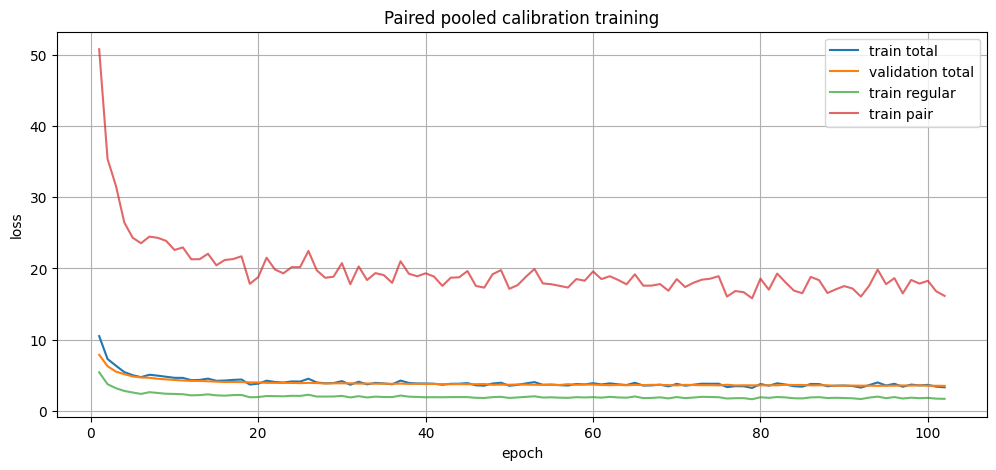

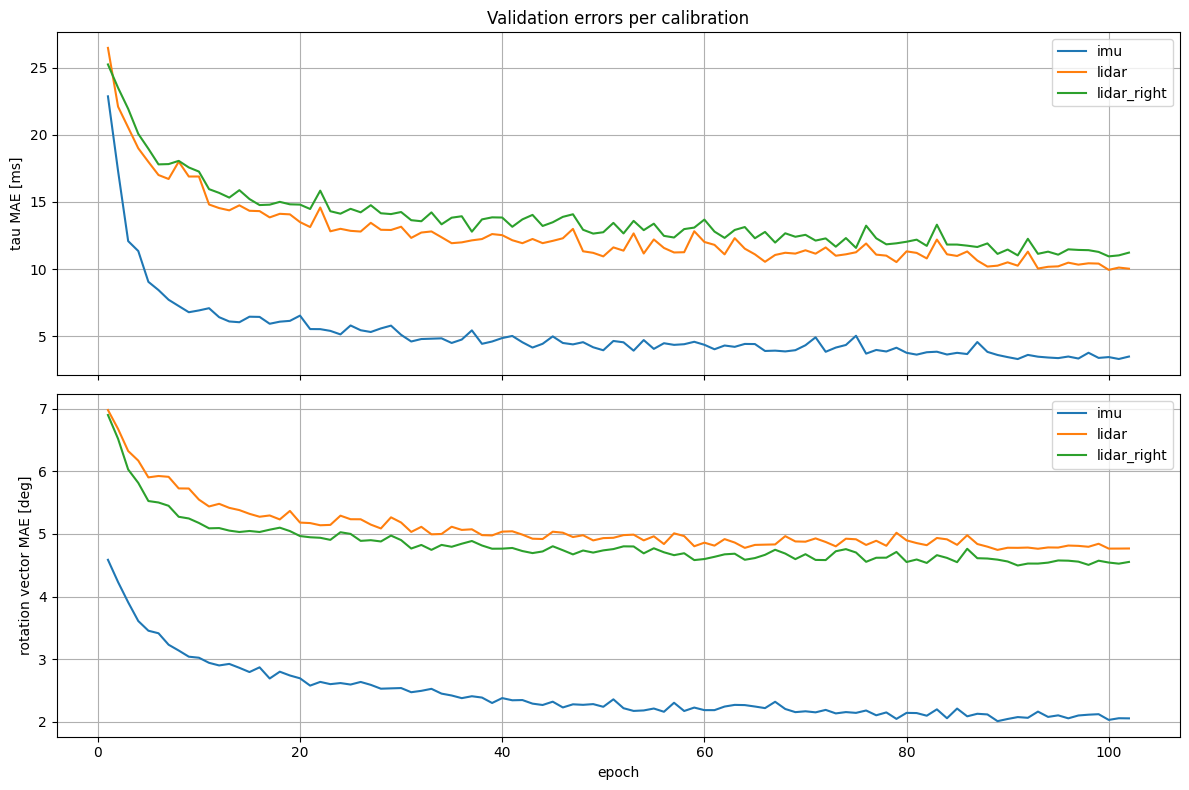

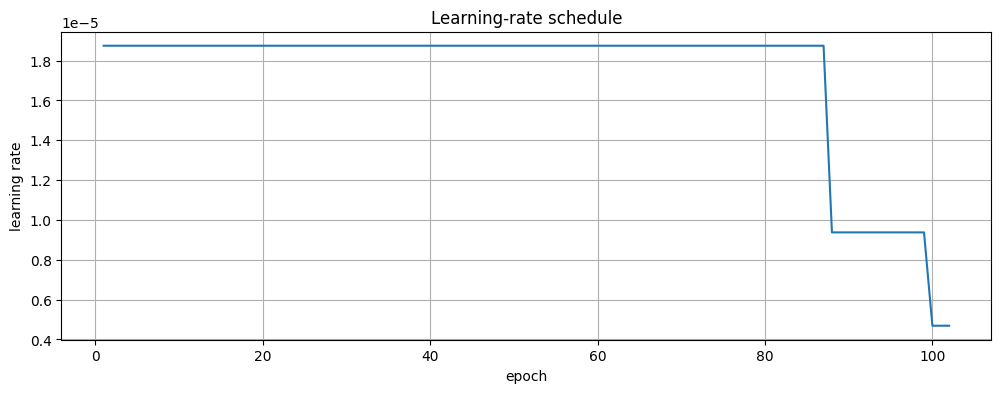

In [102]:
if history:
    epochs = [row["epoch"] for row in history]

    plt.figure(figsize=(12, 5))
    plt.plot(epochs, [row["train/loss_total"] for row in history], label="train total")
    plt.plot(epochs, [row["val/loss_total"] for row in history], label="validation total")
    plt.plot(epochs, [row["train/loss_regular"] for row in history], label="train regular", alpha=0.7)
    plt.plot(epochs, [row["train/loss_pair"] for row in history], label="train pair", alpha=0.7)
    plt.xlabel("epoch")
    plt.ylabel("loss")
    plt.title("Paired pooled calibration training")
    plt.grid(True)
    plt.legend()
    plt.show()

    # New: track the error of every calibration separately on the full validation set.
    fig, axes = plt.subplots(2, 1, figsize=(12, 8), sharex=True)
    for calibration_key in CALIBRATION_KEYS:
        axes[0].plot(epochs, [row[f"val/mean/{calibration_key}/time_offset_error_ms"] for row in history], label=calibration_key)
        axes[1].plot(epochs, [row[f"val/mean/{calibration_key}/rotation_error_deg"] for row in history], label=calibration_key)
    axes[0].set_ylabel("tau MAE [ms]")
    axes[1].set_ylabel("rotation vector MAE [deg]")
    axes[1].set_xlabel("epoch")
    axes[0].set_title("Validation errors per calibration")
    for ax in axes:
        ax.grid(True)
        ax.legend()
    fig.tight_layout()
    plt.show()

    plt.figure(figsize=(12, 4))
    plt.plot(epochs, [row["learning_rate"] for row in history])
    plt.xlabel("epoch")
    plt.ylabel("learning rate")
    plt.title("Learning-rate schedule")
    plt.grid(True)
    plt.show()
torch.cuda.empty_cache()

## 19. Evaluate the best checkpoint


In [105]:
if BEST_CHECKPOINT_PATH.exists():
    best_checkpoint = load_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)
    test_pair_generator = make_augmentation_generator(TEST_PAIR_SEED)
    test_metrics, _ = run_paired_epoch(test_loader, training=False, pair_generator=test_pair_generator, global_step=global_step)

    print("Best checkpoint epoch:", best_checkpoint.get("epoch"))
    print("Test metrics:")
    for key in sorted(test_metrics):
        print(f"  {key}: {test_metrics[key]:.6f}")
else:
    print("No best checkpoint exists yet.")


Best checkpoint epoch: 89
Test metrics:
  epoch_time_s: 128.703061
  loss_pair: 13.157621
  loss_regular: 1.429371
  loss_total: 2.745133
  loss_truth: 0.000000
  mean/imu/loss_rotation: 0.153106
  mean/imu/loss_time_offset: 0.015493
  mean/imu/loss_translation: 0.000589
  mean/imu/rotation_error_deg: 1.661078
  mean/imu/time_offset_error_ms: 3.391273
  mean/imu/translation_error_cm: 0.093865
  mean/lidar/loss_rotation: 0.841005
  mean/lidar/loss_time_offset: 0.087490
  mean/lidar/loss_translation: 0.000299
  mean/lidar/rotation_error_deg: 4.004256
  mean/lidar/time_offset_error_ms: 9.445690
  mean/lidar/translation_error_cm: 0.082248
  mean/lidar_right/loss_rotation: 1.056191
  mean/lidar_right/loss_time_offset: 0.083402
  mean/lidar_right/loss_translation: 0.000238
  mean/lidar_right/rotation_error_deg: 4.247861
  mean/lidar_right/time_offset_error_ms: 9.299679
  mean/lidar_right/translation_error_cm: 0.074730
  negative/imu/loss_rotation: 0.145436
  negative/imu/loss_time_offset: 0.

## 20. Select held-out windows for detailed visualization


In [106]:
VIS_SEQUENCE_NAME = "Urban38"
VIS_START_WINDOW = 0
VIS_NUM_WINDOWS = 100
VIS_BATCH_SIZE = 16

sequence_indices = [index for index in range(len(test_dataset)) if test_dataset.sequence_name_for_window(index) == VIS_SEQUENCE_NAME]

if not sequence_indices:
    raise ValueError(f"Sequence {VIS_SEQUENCE_NAME!r} is not present in test_dataset.")

selected_indices = sequence_indices[VIS_START_WINDOW : VIS_START_WINDOW + VIS_NUM_WINDOWS]

print("Sequence:", VIS_SEQUENCE_NAME)
print("Selected windows:", len(selected_indices))
print("Dataset indices:", selected_indices[0], "...", selected_indices[-1])


Sequence: Urban38
Selected windows: 100
Dataset indices: 0 ... 99


## 21. Collect deterministic paired predictions


In [107]:
def collect_paired_predictions(dataset, indices, *, batch_size, pair_seed):
    model.eval()
    pair_generator = make_augmentation_generator(pair_seed)

    collected = {
        calibration_key: {
            "positive_true_xi": [],
            "positive_predicted_xi": [],
            "positive_true_tau": [],
            "positive_predicted_tau": [],
            "negative_true_xi": [],
            "negative_predicted_xi": [],
            "negative_true_tau": [],
            "negative_predicted_tau": [],
        }
        for calibration_key in CALIBRATION_KEYS
    }

    with torch.no_grad():
        for start in range(0, len(indices), batch_size):
            batch_indices = indices[start : start + batch_size]
            base_window = collate_windows([dataset[index] for index in batch_indices])
            base_window = window_batch_to(base_window, DEVICE, dtype=MODEL_DTYPE)

            positive_window, negative_window, _, _ = make_paired_windows(base_window, generator=pair_generator)
            positive_result = window_step(positive_window)
            negative_result = window_step(negative_window)

            for calibration_key in CALIBRATION_KEYS:
                positive_true_xi, positive_true_tau = correction_target(positive_window, calibration_key)
                negative_true_xi, negative_true_tau = correction_target(negative_window, calibration_key)

                positive_prediction = positive_result.model_output.predictions[calibration_key]
                negative_prediction = negative_result.model_output.predictions[calibration_key]

                collected[calibration_key]["positive_true_xi"].append(positive_true_xi.detach().cpu())
                collected[calibration_key]["positive_predicted_xi"].append(positive_prediction.delta_xi.detach().cpu())
                collected[calibration_key]["positive_true_tau"].append(positive_true_tau.detach().cpu())
                collected[calibration_key]["positive_predicted_tau"].append(positive_prediction.delta_tau.detach().cpu())

                collected[calibration_key]["negative_true_xi"].append(negative_true_xi.detach().cpu())
                collected[calibration_key]["negative_predicted_xi"].append(negative_prediction.delta_xi.detach().cpu())
                collected[calibration_key]["negative_true_tau"].append(negative_true_tau.detach().cpu())
                collected[calibration_key]["negative_predicted_tau"].append(negative_prediction.delta_tau.detach().cpu())

    for calibration_key in CALIBRATION_KEYS:
        for field_name in collected[calibration_key]:
            collected[calibration_key][field_name] = torch.cat(collected[calibration_key][field_name], dim=0).numpy()

    return collected


if BEST_CHECKPOINT_PATH.exists():
    load_training_checkpoint(BEST_CHECKPOINT_PATH, model=model, map_location=DEVICE, restore_rng_state=False)

visualization_results = collect_paired_predictions(test_dataset, selected_indices, batch_size=VIS_BATCH_SIZE, pair_seed=VISUALIZATION_PAIR_SEED)


## 22. True vs predicted correction over windows


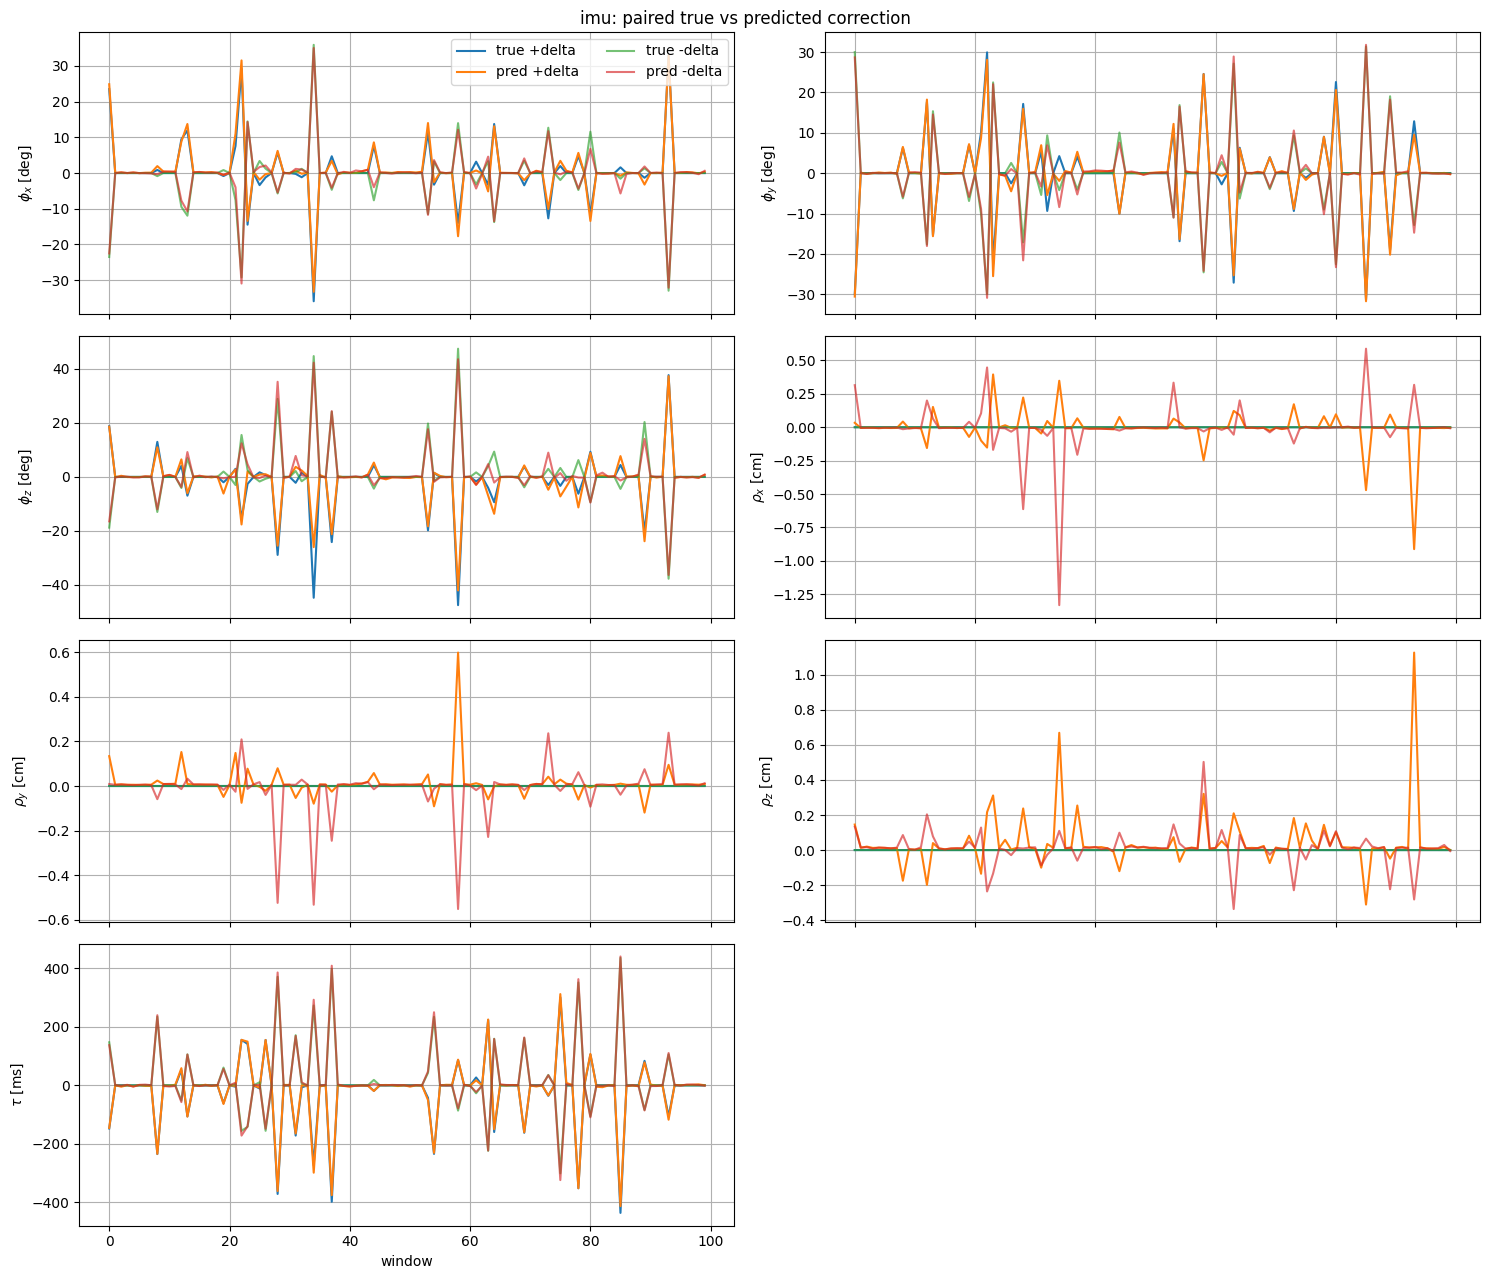

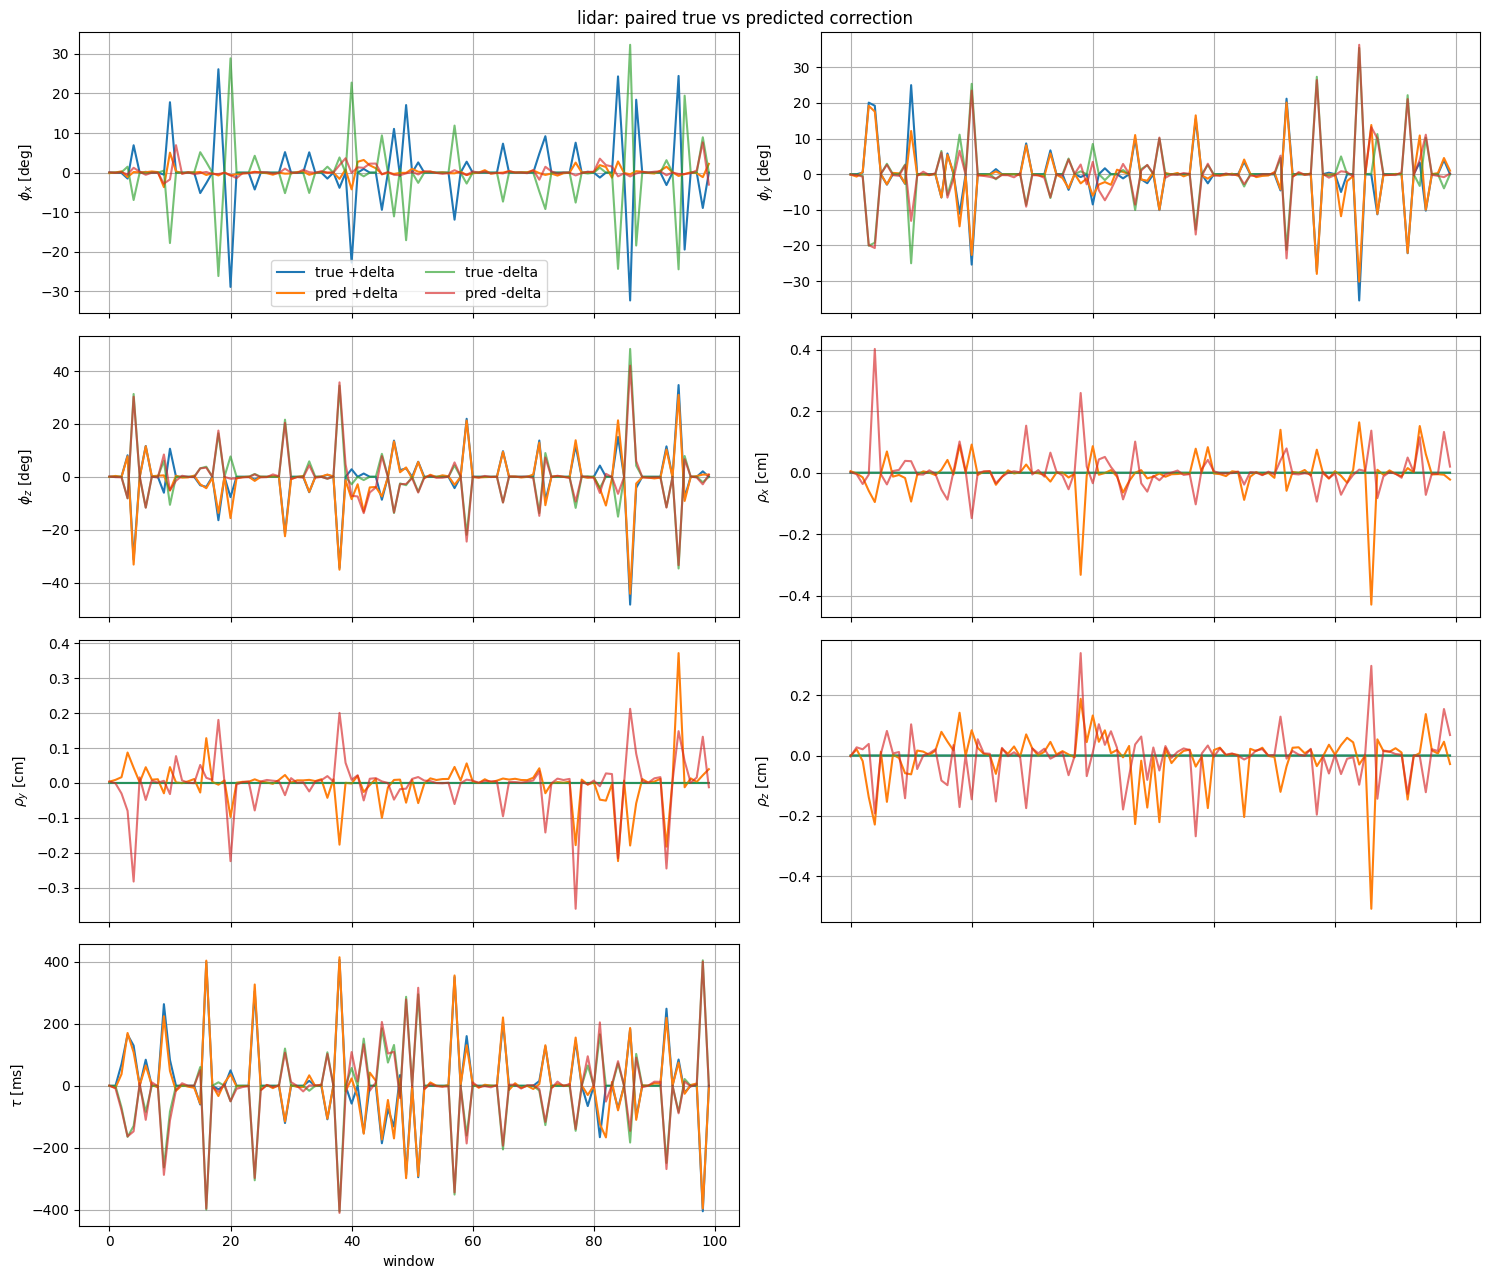

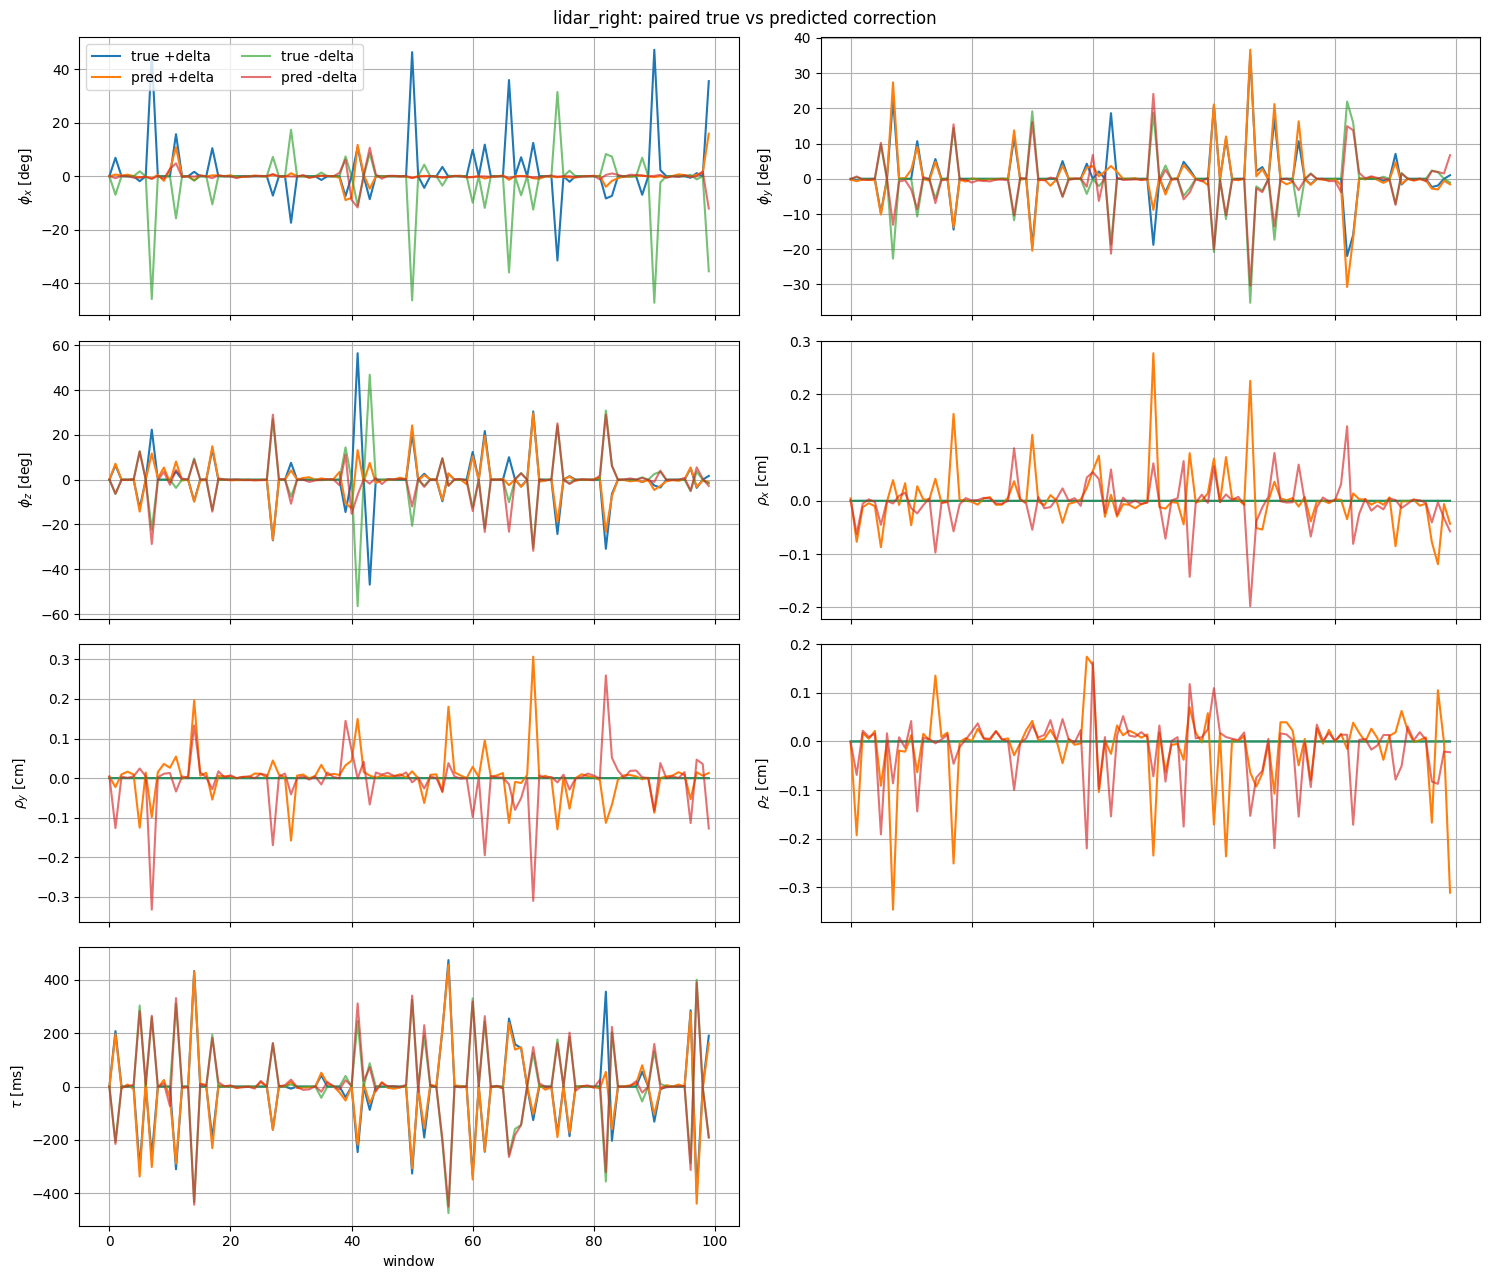

In [108]:
def physical_correction_values(xi, tau):
    return np.column_stack([np.rad2deg(xi[:, :3]), 100.0 * xi[:, 3:], 1000.0 * tau.reshape(-1)])


def plot_paired_true_vs_predicted(results, calibration_key):
    result = results[calibration_key]

    positive_true = physical_correction_values(result["positive_true_xi"], result["positive_true_tau"])
    positive_predicted = physical_correction_values(result["positive_predicted_xi"], result["positive_predicted_tau"])
    negative_true = physical_correction_values(result["negative_true_xi"], result["negative_true_tau"])
    negative_predicted = physical_correction_values(result["negative_predicted_xi"], result["negative_predicted_tau"])

    component_names = (r"$\phi_x$", r"$\phi_y$", r"$\phi_z$", r"$\rho_x$", r"$\rho_y$", r"$\rho_z$", r"$\tau$")
    units = ("deg", "deg", "deg", "cm", "cm", "cm", "ms")
    x = np.arange(len(positive_true))

    fig, axes = plt.subplots(4, 2, figsize=(15, 13), sharex=True)
    axes = axes.ravel()

    for component_index in range(7):
        ax = axes[component_index]
        ax.plot(x, positive_true[:, component_index], label="true +delta")
        ax.plot(x, positive_predicted[:, component_index], label="pred +delta")
        ax.plot(x, negative_true[:, component_index], label="true -delta", alpha=0.65)
        ax.plot(x, negative_predicted[:, component_index], label="pred -delta", alpha=0.65)
        ax.set_ylabel(f"{component_names[component_index]} [{units[component_index]}]")
        ax.grid(True)

        if component_index == 0:
            ax.legend(ncol=2)

    axes[6].set_xlabel("window")
    axes[7].axis("off")
    fig.suptitle(f"{calibration_key}: paired true vs predicted correction")
    fig.tight_layout()
    plt.show()


for calibration_key in CALIBRATION_KEYS:
    plot_paired_true_vs_predicted(visualization_results, calibration_key)


## 23. Combined true-vs-predicted scatter


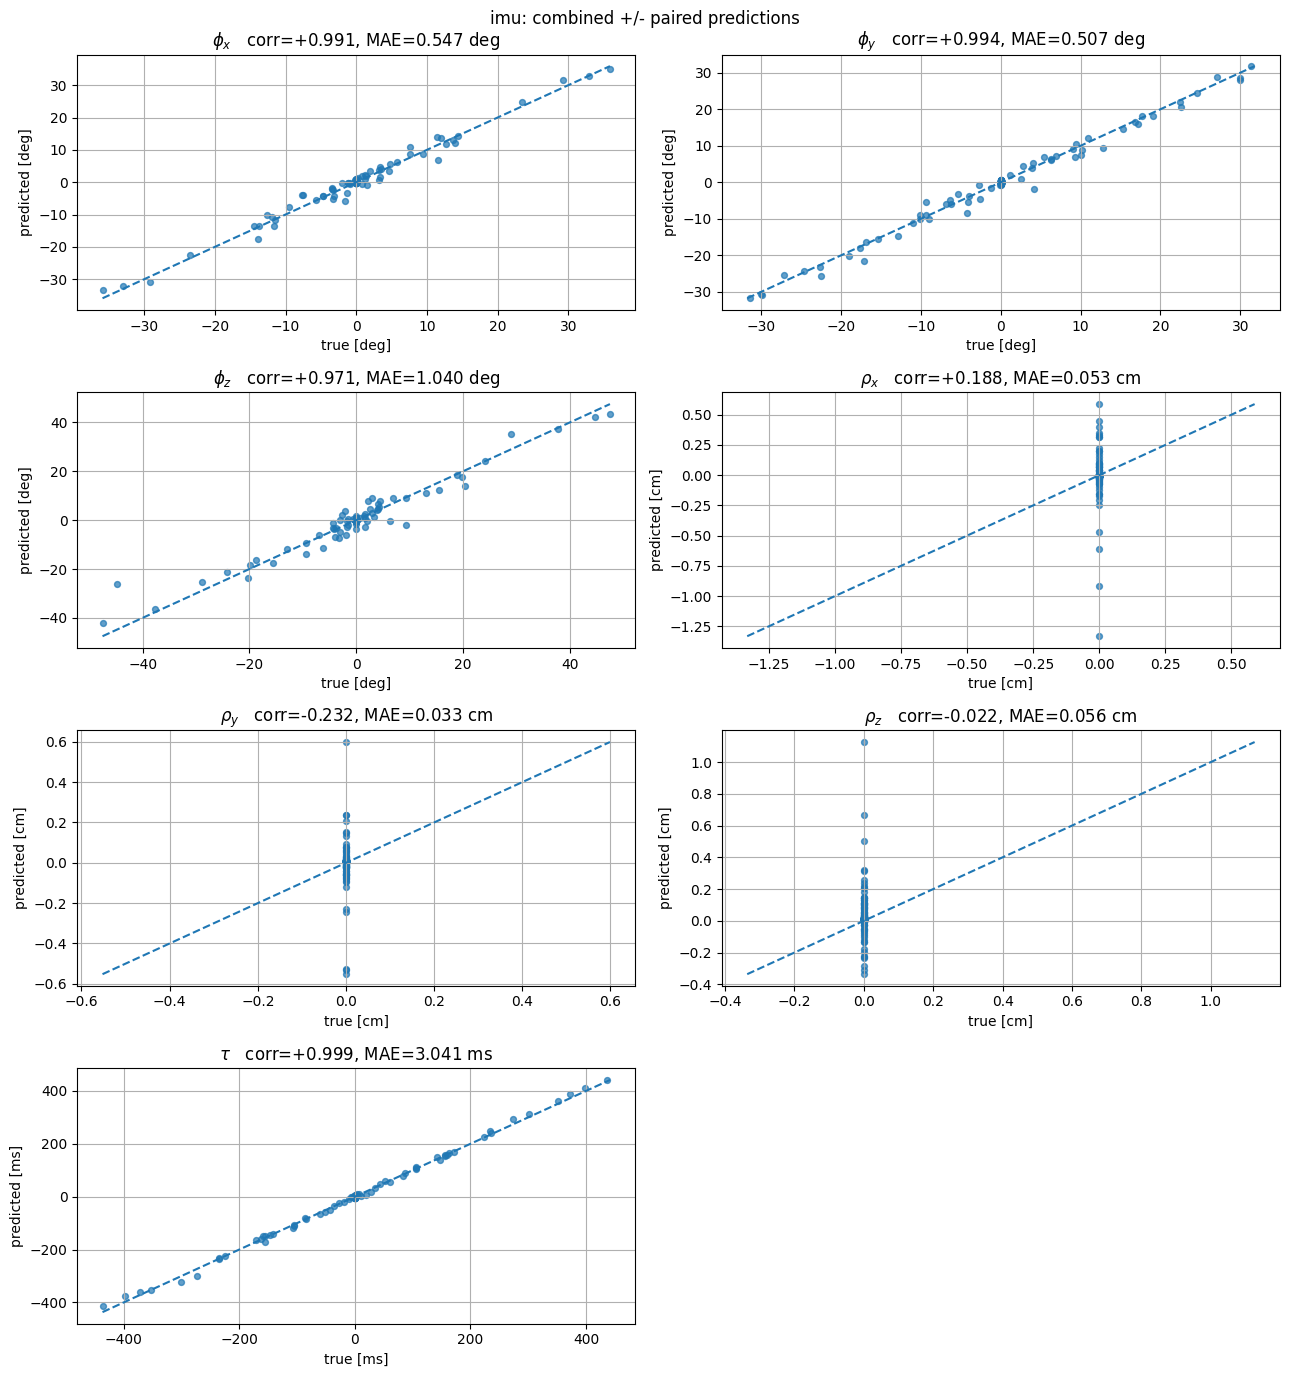

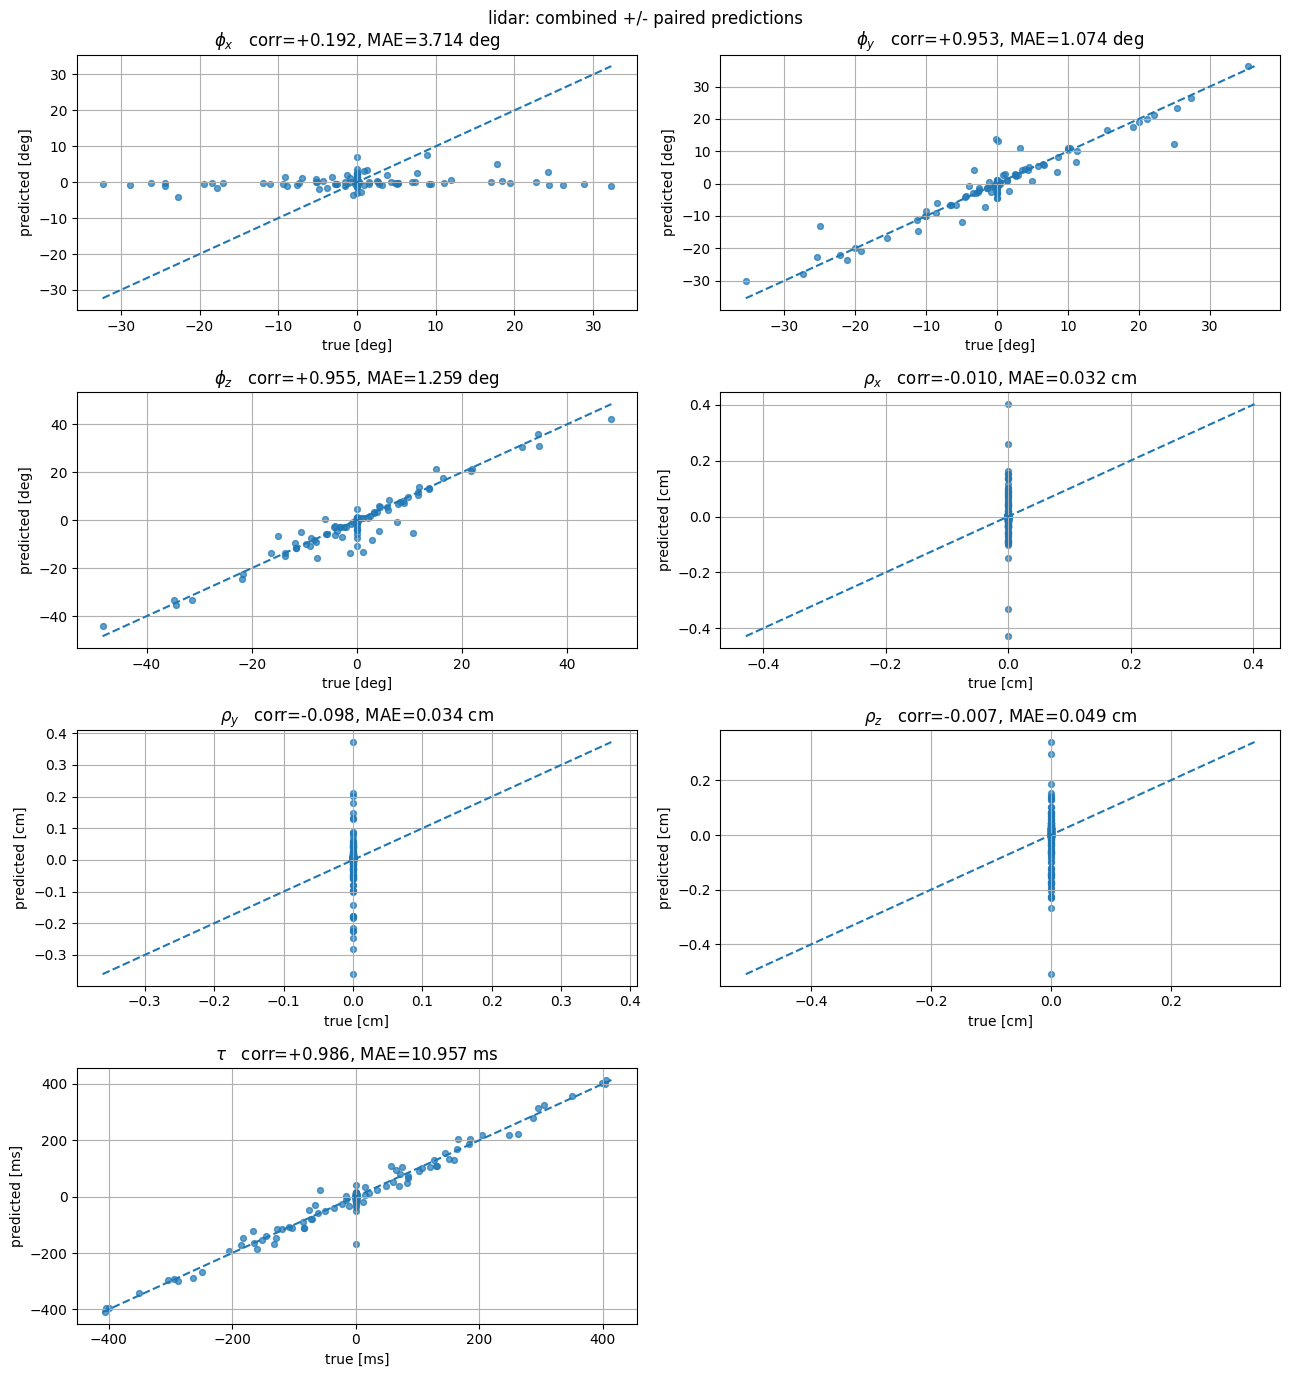

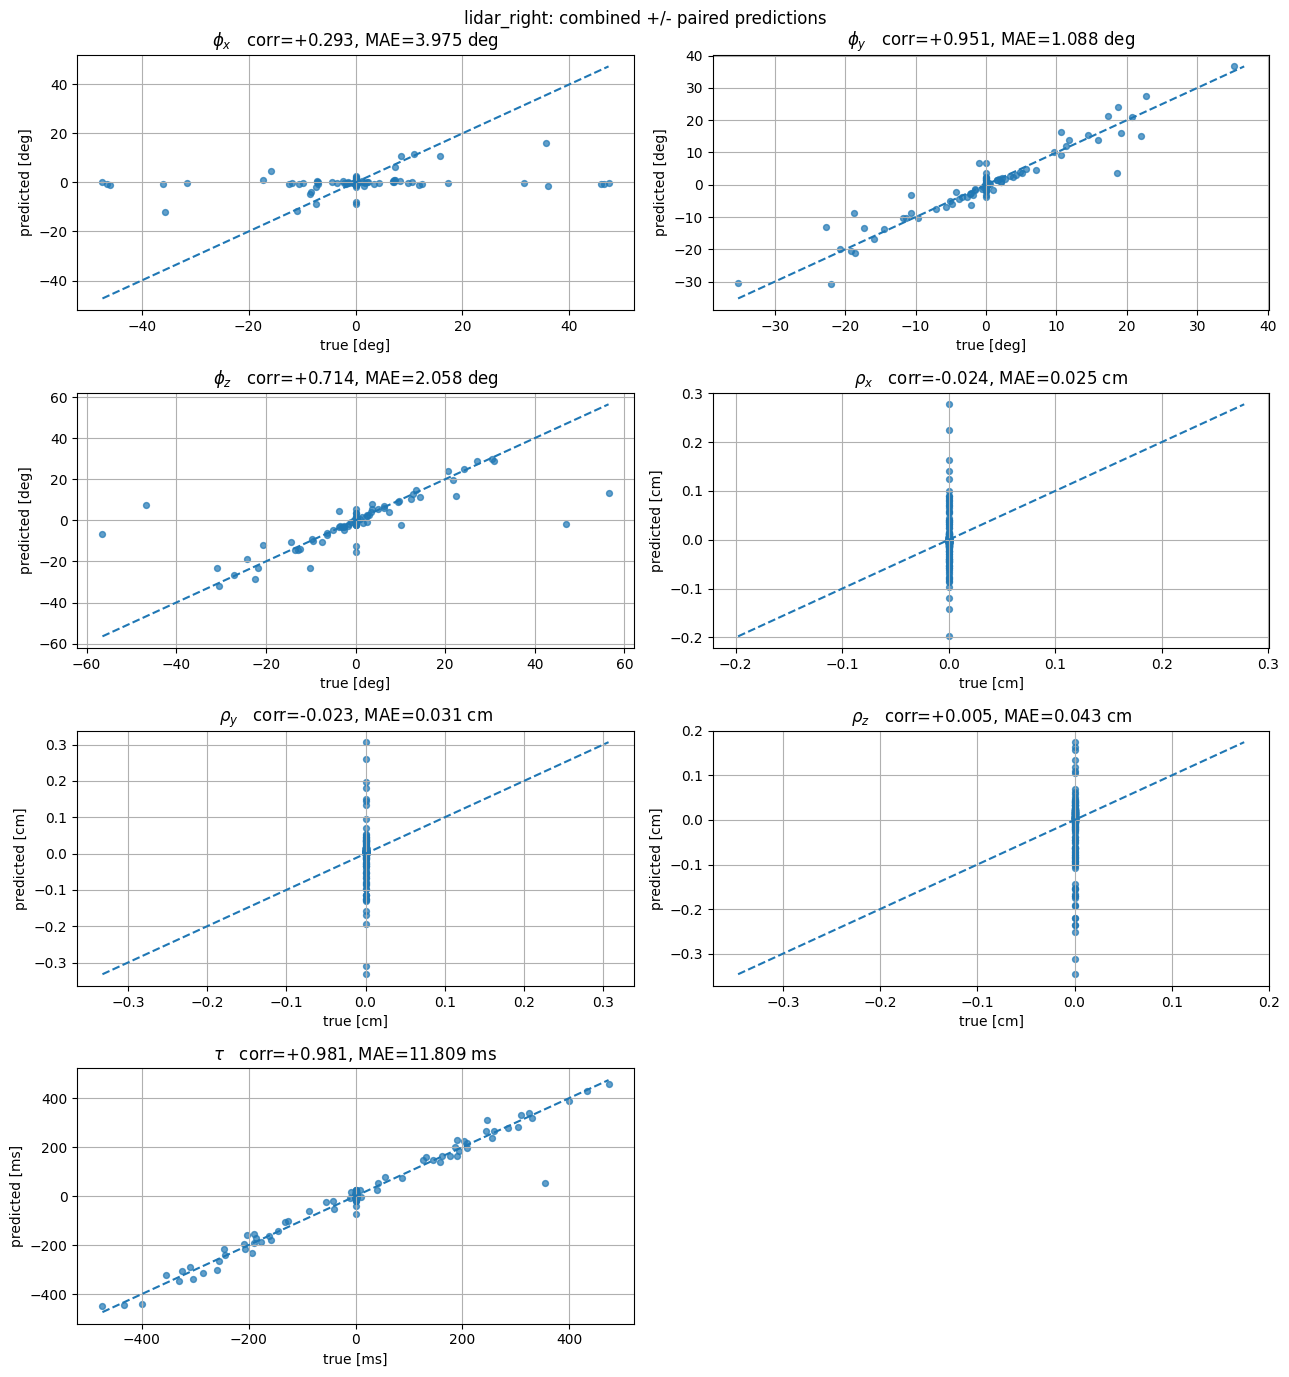

In [109]:
def plot_combined_true_vs_predicted_scatter(results, calibration_key):
    result = results[calibration_key]

    positive_true = physical_correction_values(result["positive_true_xi"], result["positive_true_tau"])
    positive_predicted = physical_correction_values(result["positive_predicted_xi"], result["positive_predicted_tau"])
    negative_true = physical_correction_values(result["negative_true_xi"], result["negative_true_tau"])
    negative_predicted = physical_correction_values(result["negative_predicted_xi"], result["negative_predicted_tau"])

    truth = np.concatenate([positive_true, negative_true], axis=0)
    prediction = np.concatenate([positive_predicted, negative_predicted], axis=0)

    component_names = (r"$\phi_x$", r"$\phi_y$", r"$\phi_z$", r"$\rho_x$", r"$\rho_y$", r"$\rho_z$", r"$\tau$")
    units = ("deg", "deg", "deg", "cm", "cm", "cm", "ms")

    fig, axes = plt.subplots(4, 2, figsize=(13, 14))
    axes = axes.ravel()

    for component_index in range(7):
        ax = axes[component_index]
        component_truth = truth[:, component_index]
        component_prediction = prediction[:, component_index]

        minimum = min(component_truth.min(), component_prediction.min())
        maximum = max(component_truth.max(), component_prediction.max())
        correlation = np.corrcoef(component_truth, component_prediction)[0, 1] if np.std(component_truth) > 0.0 and np.std(component_prediction) > 0.0 else np.nan
        mae = np.mean(np.abs(component_prediction - component_truth))

        ax.scatter(component_truth, component_prediction, s=18, alpha=0.7)
        ax.plot([minimum, maximum], [minimum, maximum], linestyle="--")
        ax.set_xlabel(f"true [{units[component_index]}]")
        ax.set_ylabel(f"predicted [{units[component_index]}]")
        ax.set_title(f"{component_names[component_index]}   corr={correlation:+.3f}, MAE={mae:.3f} {units[component_index]}")
        ax.grid(True)

    axes[7].axis("off")
    fig.suptitle(f"{calibration_key}: combined +/- paired predictions")
    fig.tight_layout()
    plt.show()


for calibration_key in CALIBRATION_KEYS:
    plot_combined_true_vs_predicted_scatter(visualization_results, calibration_key)


## 24. Pair-difference scatter

This is the most important anti-collapse visualization. A constant predictor produces approximately zero pair difference and therefore a horizontal cloud. A useful paired model should approach the identity diagonal.


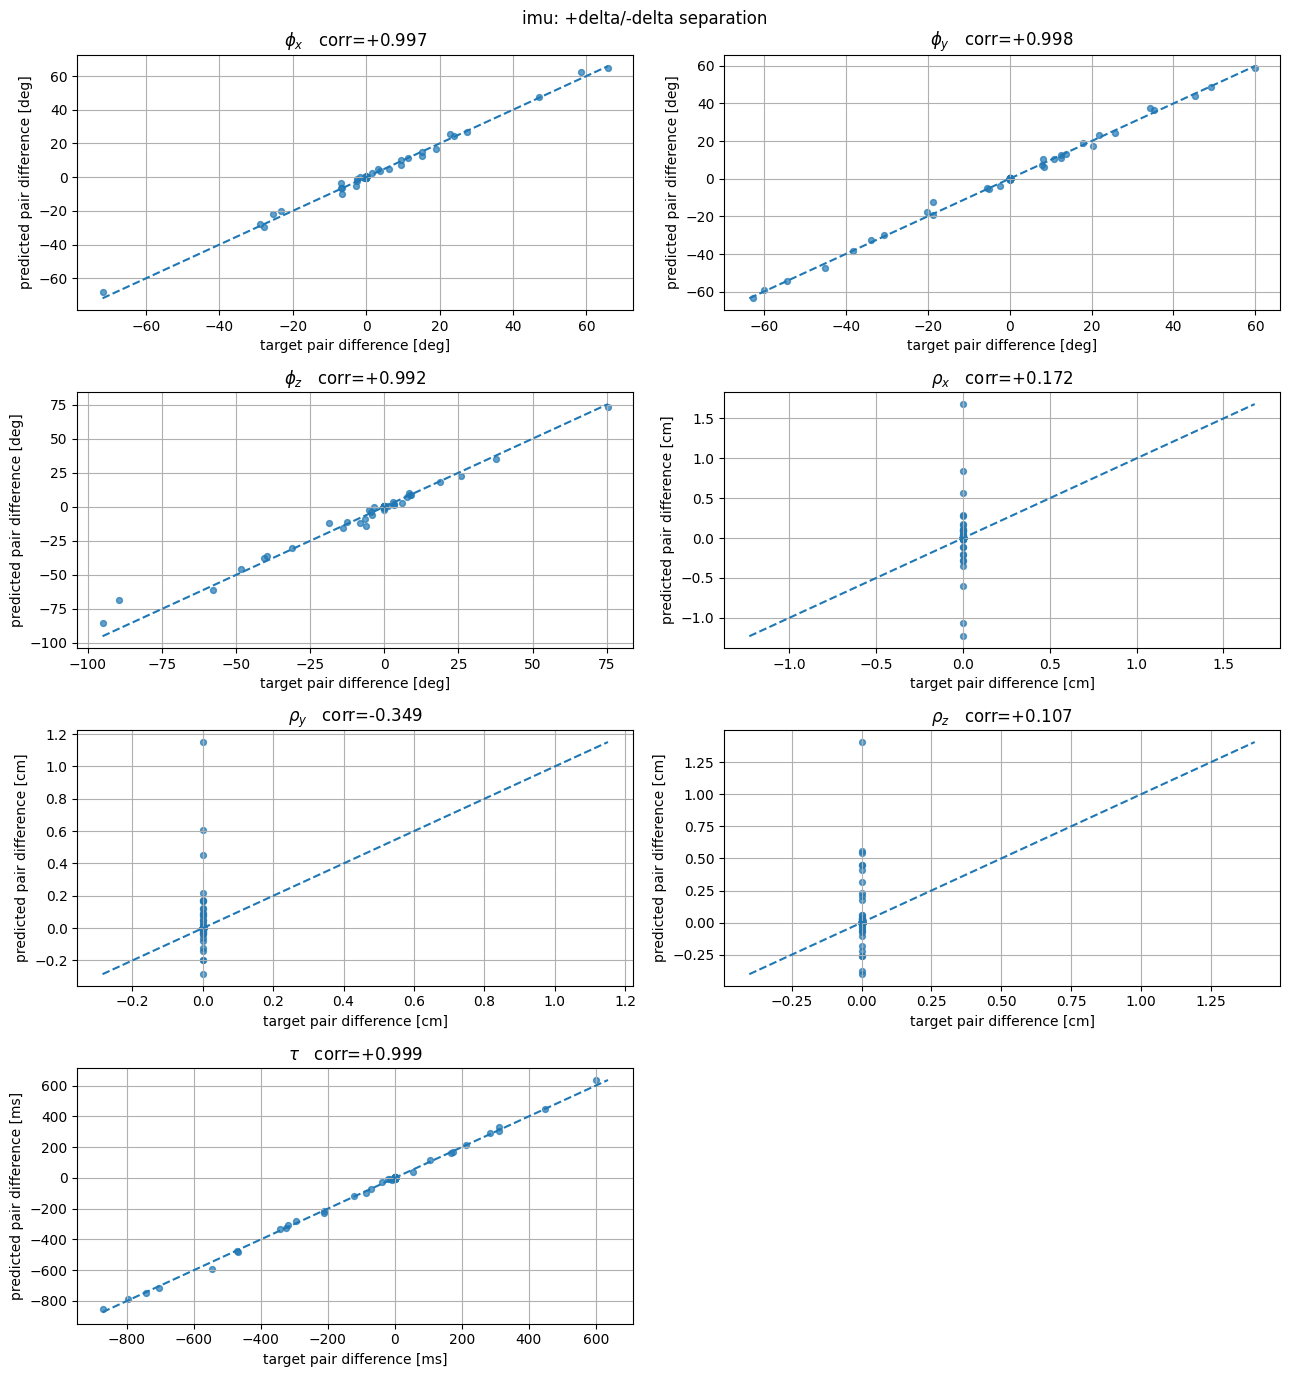

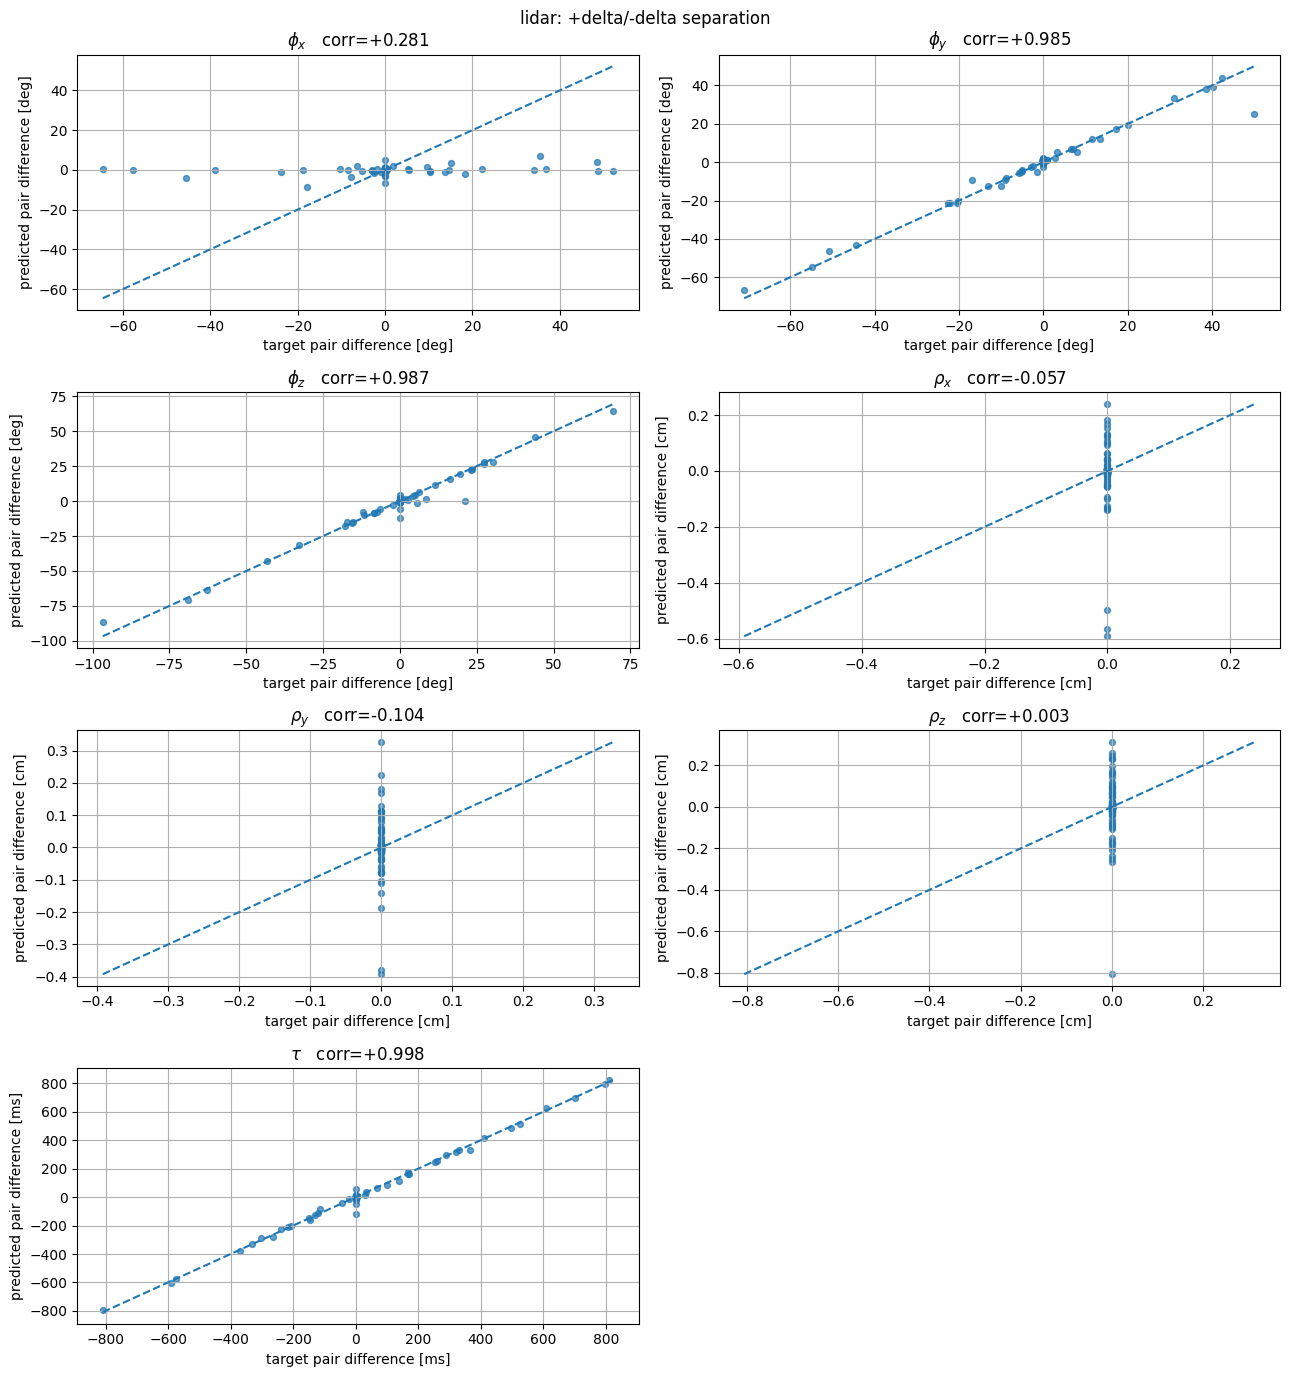

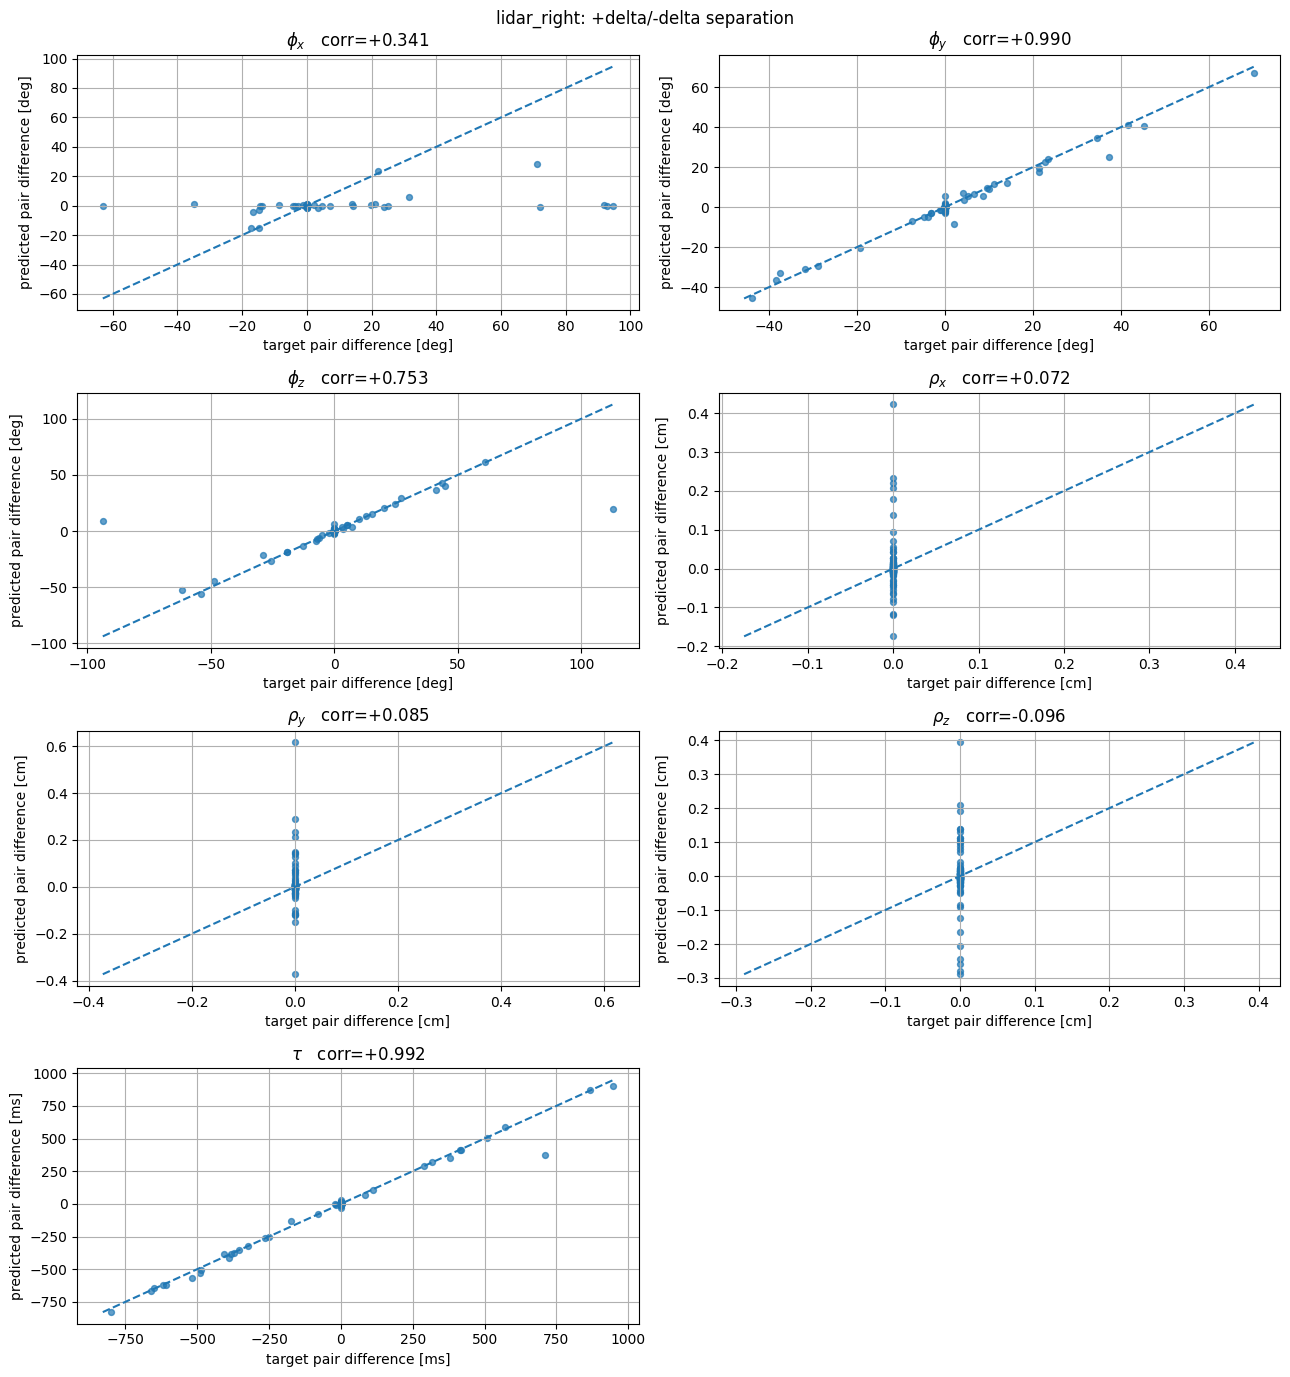

In [110]:
def plot_pair_difference_scatter(results, calibration_key):
    result = results[calibration_key]

    positive_true = physical_correction_values(result["positive_true_xi"], result["positive_true_tau"])
    positive_predicted = physical_correction_values(result["positive_predicted_xi"], result["positive_predicted_tau"])
    negative_true = physical_correction_values(result["negative_true_xi"], result["negative_true_tau"])
    negative_predicted = physical_correction_values(result["negative_predicted_xi"], result["negative_predicted_tau"])

    target_difference = positive_true - negative_true
    predicted_difference = positive_predicted - negative_predicted

    component_names = (r"$\phi_x$", r"$\phi_y$", r"$\phi_z$", r"$\rho_x$", r"$\rho_y$", r"$\rho_z$", r"$\tau$")
    units = ("deg", "deg", "deg", "cm", "cm", "cm", "ms")

    fig, axes = plt.subplots(4, 2, figsize=(13, 14))
    axes = axes.ravel()

    for component_index in range(7):
        ax = axes[component_index]
        truth = target_difference[:, component_index]
        prediction = predicted_difference[:, component_index]

        minimum = min(truth.min(), prediction.min())
        maximum = max(truth.max(), prediction.max())
        correlation = np.corrcoef(truth, prediction)[0, 1] if np.std(truth) > 0.0 and np.std(prediction) > 0.0 else np.nan

        ax.scatter(truth, prediction, s=18, alpha=0.7)
        ax.plot([minimum, maximum], [minimum, maximum], linestyle="--")
        ax.set_xlabel(f"target pair difference [{units[component_index]}]")
        ax.set_ylabel(f"predicted pair difference [{units[component_index]}]")
        ax.set_title(f"{component_names[component_index]}   corr={correlation:+.3f}")
        ax.grid(True)

    axes[7].axis("off")
    fig.suptitle(f"{calibration_key}: +delta/-delta separation")
    fig.tight_layout()
    plt.show()


for calibration_key in CALIBRATION_KEYS:
    plot_pair_difference_scatter(visualization_results, calibration_key)


## 25. Numerical paired-prediction summary


In [111]:
def print_paired_prediction_summary(results, calibration_key):
    result = results[calibration_key]

    positive_true = physical_correction_values(result["positive_true_xi"], result["positive_true_tau"])
    positive_predicted = physical_correction_values(result["positive_predicted_xi"], result["positive_predicted_tau"])
    negative_true = physical_correction_values(result["negative_true_xi"], result["negative_true_tau"])
    negative_predicted = physical_correction_values(result["negative_predicted_xi"], result["negative_predicted_tau"])

    truth = np.concatenate([positive_true, negative_true], axis=0)
    prediction = np.concatenate([positive_predicted, negative_predicted], axis=0)
    target_difference = positive_true - negative_true
    predicted_difference = positive_predicted - negative_predicted

    component_names = ("phi_x", "phi_y", "phi_z", "rho_x", "rho_y", "rho_z", "tau")
    units = ("deg", "deg", "deg", "cm", "cm", "cm", "ms")

    print(calibration_key)
    print(f"{'component':8s} {'MAE':>12s} {'corr':>10s} {'pred std':>12s} {'pair corr':>12s} {'pair MAE':>12s}")

    for component_index, component_name in enumerate(component_names):
        component_truth = truth[:, component_index]
        component_prediction = prediction[:, component_index]
        difference_truth = target_difference[:, component_index]
        difference_prediction = predicted_difference[:, component_index]

        mae = np.mean(np.abs(component_prediction - component_truth))
        correlation = np.corrcoef(component_truth, component_prediction)[0, 1] if np.std(component_truth) > 0.0 and np.std(component_prediction) > 0.0 else np.nan
        pair_correlation = np.corrcoef(difference_truth, difference_prediction)[0, 1] if np.std(difference_truth) > 0.0 and np.std(difference_prediction) > 0.0 else np.nan
        pair_mae = np.mean(np.abs(difference_prediction - difference_truth))

        print(
            f"{component_name:8s} "
            f"{mae:9.4f} {units[component_index]:3s} "
            f"{correlation:+10.4f} "
            f"{np.std(component_prediction):12.4f} "
            f"{pair_correlation:+12.4f} "
            f"{pair_mae:9.4f} {units[component_index]:3s}"
        )

    print()


for calibration_key in CALIBRATION_KEYS:
    print_paired_prediction_summary(visualization_results, calibration_key)


imu
component          MAE       corr     pred std    pair corr     pair MAE
phi_x       0.5472 deg    +0.9909       7.2500      +0.9972    0.5488 deg
phi_y       0.5071 deg    +0.9937       8.7280      +0.9983    0.4900 deg
phi_z       1.0397 deg    +0.9713       8.8821      +0.9923    1.0753 deg
rho_x       0.0529 cm     +0.1878       0.1556      +0.1725    0.0928 cm 
rho_y       0.0331 cm     -0.2320       0.0917      -0.3488    0.0503 cm 
rho_z       0.0563 cm     -0.0221       0.1264      +0.1074    0.0728 cm 
tau         3.0410 ms     +0.9988     109.0389      +0.9994    4.2038 ms 

lidar
component          MAE       corr     pred std    pair corr     pair MAE
phi_x       3.7140 deg    +0.1920       1.2483      +0.2807    7.0336 deg
phi_y       1.0738 deg    +0.9528       7.6104      +0.9851    1.0091 deg
phi_z       1.2591 deg    +0.9551       9.2188      +0.9869    1.1678 deg
rho_x       0.0323 cm     -0.0105       0.0673      -0.0574    0.0493 cm 
rho_y       0.0342 cm     -0.

## 25a. Compare time-offset corrections across all sensors

Plot all three clocks side by side. The second figure evaluates **relative correction differences** for each sensor pair; these are useful diagnostics because a common time shift is not identifiable from relative motion alone. The plots show predictive behavior, not production fault classification.


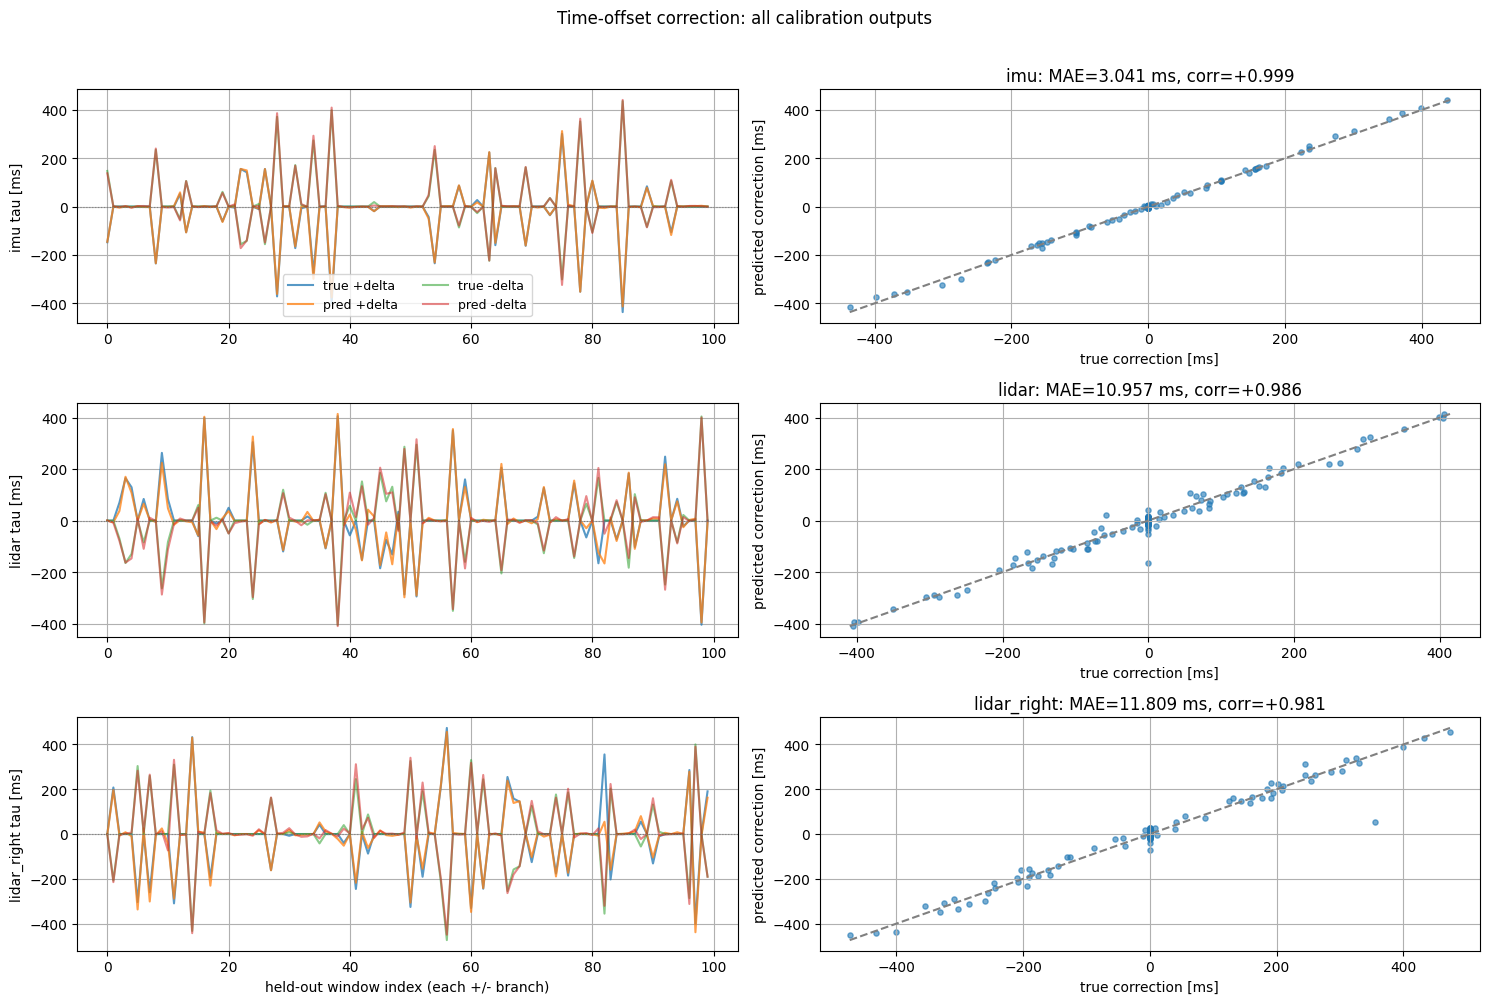

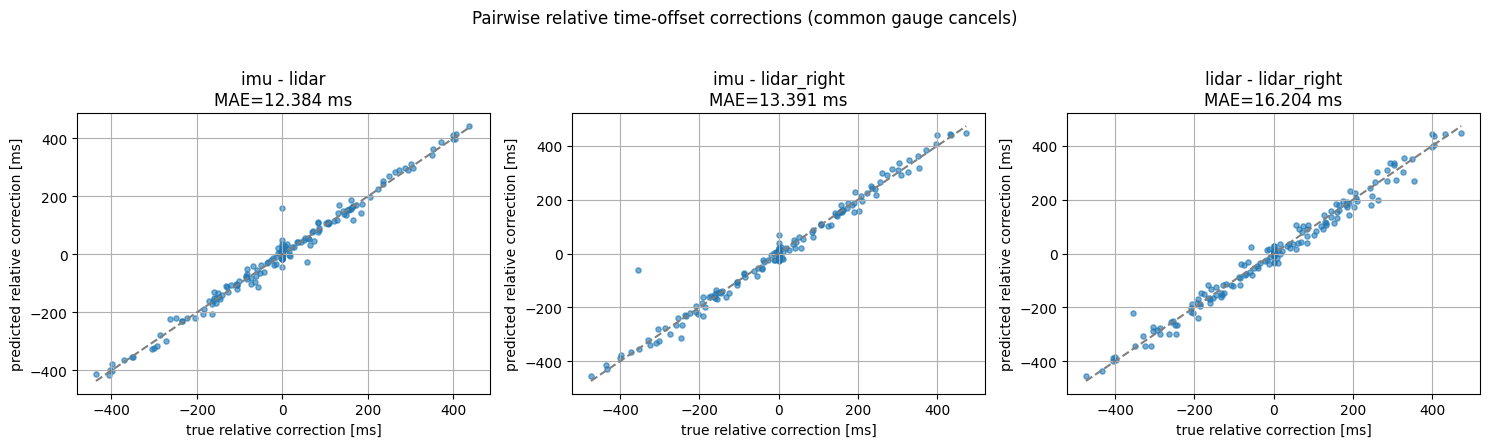

In [112]:
# Three-sensor timing comparison using the exact paired predictions collected above.
from itertools import combinations


def _paired_tau_arrays(results, calibration_key):
    result = results[calibration_key]
    return (
        1000.0 * np.concatenate((result["positive_true_tau"].reshape(-1), result["negative_true_tau"].reshape(-1))),
        1000.0 * np.concatenate((result["positive_predicted_tau"].reshape(-1), result["negative_predicted_tau"].reshape(-1))),
    )


def plot_three_sensor_tau_comparison(results):
    fig, axes = plt.subplots(len(CALIBRATION_KEYS), 2, figsize=(15, 3.3 * len(CALIBRATION_KEYS)), squeeze=False)

    for row, calibration_key in enumerate(CALIBRATION_KEYS):
        true_tau, predicted_tau = _paired_tau_arrays(results, calibration_key)
        true_positive = 1000.0 * results[calibration_key]["positive_true_tau"].reshape(-1)
        predicted_positive = 1000.0 * results[calibration_key]["positive_predicted_tau"].reshape(-1)
        true_negative = 1000.0 * results[calibration_key]["negative_true_tau"].reshape(-1)
        predicted_negative = 1000.0 * results[calibration_key]["negative_predicted_tau"].reshape(-1)
        x = np.arange(len(true_positive))

        axes[row, 0].plot(x, true_positive, label="true +delta", alpha=0.75)
        axes[row, 0].plot(x, predicted_positive, label="pred +delta", alpha=0.75)
        axes[row, 0].plot(x, true_negative, label="true -delta", alpha=0.55)
        axes[row, 0].plot(x, predicted_negative, label="pred -delta", alpha=0.55)
        axes[row, 0].axhline(0.0, color="gray", linestyle=":", linewidth=0.8)
        axes[row, 0].set_ylabel(f"{calibration_key} tau [ms]")
        axes[row, 0].grid(True)
        if row == 0:
            axes[row, 0].legend(ncol=2, fontsize=9)

        minimum = min(true_tau.min(), predicted_tau.min())
        maximum = max(true_tau.max(), predicted_tau.max())
        axes[row, 1].scatter(true_tau, predicted_tau, s=14, alpha=0.6)
        axes[row, 1].plot([minimum, maximum], [minimum, maximum], linestyle="--", color="gray")
        axes[row, 1].set_xlabel("true correction [ms]")
        axes[row, 1].set_ylabel("predicted correction [ms]")
        corr = np.corrcoef(true_tau, predicted_tau)[0, 1] if np.std(true_tau) > 0 and np.std(predicted_tau) > 0 else np.nan
        axes[row, 1].set_title(f"{calibration_key}: MAE={np.mean(np.abs(predicted_tau - true_tau)):.3f} ms, corr={corr:+.3f}")
        axes[row, 1].grid(True)

    axes[-1, 0].set_xlabel("held-out window index (each +/- branch)")
    fig.suptitle("Time-offset correction: all calibration outputs", y=1.01)
    fig.tight_layout()
    plt.show()


def plot_relative_tau_corrections(results):
    sensor_pairs = list(combinations(CALIBRATION_KEYS, 2))
    fig, axes = plt.subplots(1, len(sensor_pairs), figsize=(5.0 * len(sensor_pairs), 4.3), squeeze=False)

    for ax, (first_key, second_key) in zip(axes.ravel(), sensor_pairs):
        first_true, first_predicted = _paired_tau_arrays(results, first_key)
        second_true, second_predicted = _paired_tau_arrays(results, second_key)
        relative_true = first_true - second_true
        relative_predicted = first_predicted - second_predicted
        minimum = min(relative_true.min(), relative_predicted.min())
        maximum = max(relative_true.max(), relative_predicted.max())
        ax.scatter(relative_true, relative_predicted, s=14, alpha=0.6)
        ax.plot([minimum, maximum], [minimum, maximum], linestyle="--", color="gray")
        ax.set_xlabel("true relative correction [ms]")
        ax.set_ylabel("predicted relative correction [ms]")
        ax.set_title(f"{first_key} - {second_key}\nMAE={np.mean(np.abs(relative_predicted - relative_true)):.3f} ms")
        ax.grid(True)

    fig.suptitle("Pairwise relative time-offset corrections (common gauge cancels)", y=1.03)
    fig.tight_layout()
    plt.show()


plot_three_sensor_tau_comparison(visualization_results)
plot_relative_tau_corrections(visualization_results)


## 26. Exact-truth fixed-point diagnostic


In [113]:
FIXED_POINT_NUM_WINDOWS = min(100, len(sequence_indices))
fixed_point_positions = np.unique(np.linspace(0, len(sequence_indices) - 1, FIXED_POINT_NUM_WINDOWS).round().astype(int))
fixed_point_indices = np.asarray(sequence_indices)[fixed_point_positions]

fixed_point_results = {calibration_key: {"delta_xi": [], "delta_tau": []} for calibration_key in CALIBRATION_KEYS}

model.eval()

with torch.no_grad():
    for dataset_index in fixed_point_indices:
        window = window_batch_to(collate_windows([test_dataset[int(dataset_index)]]), DEVICE, dtype=MODEL_DTYPE)
        exact_true_calibration = {calibration_key: CalibrationState(transform=state.transform.clone(), time_offset=state.time_offset.clone()) for calibration_key, state in window.current_calibration.items()}
        result = window_step(window, calibration=exact_true_calibration)

        for calibration_key, prediction in result.model_output.predictions.items():
            fixed_point_results[calibration_key]["delta_xi"].append(prediction.delta_xi[0].detach().cpu())
            fixed_point_results[calibration_key]["delta_tau"].append(prediction.delta_tau[0, 0].detach().cpu())

for calibration_key in CALIBRATION_KEYS:
    fixed_point_results[calibration_key]["delta_xi"] = torch.stack(fixed_point_results[calibration_key]["delta_xi"]).numpy()
    fixed_point_results[calibration_key]["delta_tau"] = torch.stack(fixed_point_results[calibration_key]["delta_tau"]).numpy()

component_names = ("phi_x", "phi_y", "phi_z", "rho_x", "rho_y", "rho_z", "tau")

print("=" * 120)
print("EXACT-TRUTH FIXED-POINT DIAGNOSTIC")
print("=" * 120)

for calibration_key in CALIBRATION_KEYS:
    result = fixed_point_results[calibration_key]
    prediction = np.concatenate([result["delta_xi"], result["delta_tau"][:, None]], axis=1)

    print(calibration_key)
    print(f"{'component':8s} {'mean':>16s} {'mean |x|':>16s} {'RMSE':>16s} {'std':>16s} {'range':>16s}")

    for component_index, component_name in enumerate(component_names):
        values = prediction[:, component_index]

        if component_index < 3:
            values, unit = np.rad2deg(values), "deg"
        elif component_index < 6:
            values, unit = 100.0 * values, "cm"
        else:
            values, unit = 1000.0 * values, "ms"

        mean = np.mean(values)
        mean_abs = np.mean(np.abs(values))
        rmse = np.sqrt(np.mean(values ** 2))
        std = np.std(values)
        value_range = np.max(values) - np.min(values)

        print(f"{component_name:8s} {mean:+12.6f} {unit:3s} {mean_abs:12.6f} {unit:3s} {rmse:12.6f} {unit:3s} {std:12.6f} {unit:3s} {value_range:12.6f} {unit:3s}")

    print()


EXACT-TRUTH FIXED-POINT DIAGNOSTIC
imu
component             mean         mean |x|             RMSE              std            range
phi_x       +0.272035 deg     0.436534 deg     0.604620 deg     0.539965 deg     4.277647 deg
phi_y       +0.080726 deg     0.353588 deg     0.454956 deg     0.447737 deg     2.714958 deg
phi_z       +0.396043 deg     0.865778 deg     2.166823 deg     2.130322 deg    21.268549 deg
rho_x       -0.003693 cm      0.008641 cm      0.020076 cm      0.019734 cm      0.200330 cm 
rho_y       +0.011341 cm      0.011342 cm      0.018315 cm      0.014381 cm      0.123159 cm 
rho_z       +0.014486 cm      0.018415 cm      0.023347 cm      0.018309 cm      0.151299 cm 
tau         -1.241360 ms      1.794931 ms      2.350730 ms      1.996236 ms     12.564935 ms 

lidar
component             mean         mean |x|             RMSE              std            range
phi_x       +0.392404 deg     0.507276 deg     1.106868 deg     1.034977 deg     8.219337 deg
phi_y       

## 27. Interpretation gate

Use the paired stochastic small-set diagnostic before trusting a full run.

A healthy paired model should satisfy all of the following:

1. the fixed paired overfit test strongly converges;
2. the stochastic paired small-set evaluation falls substantially;
3. held-out prediction standard deviations are nonzero;
4. true-vs-predicted scatter moves toward the identity line;
5. pair-difference scatter moves toward the identity line;
6. exact-truth inputs still produce corrections close to zero.

If the paired stochastic small-set test still collapses, do not compensate by merely increasing `PAIR_LOSS_WEIGHT` indefinitely. The next architectural experiment should expose the current calibration numerically to the pooled prediction path, because the present architecture then appears unable to recover enough calibration dependence indirectly from geometry-processed measurements.


# Shuffle diagnostics of prior-only training

In [114]:
# Measurement-shuffle diagnostic.
# Keep every calibration prior and supervision target attached to its original batch item,
# but replace the complete measurement window by another item's measurement window.
# If performance barely changes, the model can solve the task mostly from calibration context alone.
# If performance degrades substantially, the model is genuinely using the sensor measurements.

from obscalib.data.structures import SensorStreamBatch, WindowBatch

MEASUREMENT_SHUFFLE_NUM_WINDOWS = min(BATCH_SIZE, 16)
MEASUREMENT_SHUFFLE_PAIR_SEED = TEST_PAIR_SEED + 700000
MEASUREMENT_SHUFFLE_PERMUTATION_SEED = TEST_PAIR_SEED + 800000

measurement_shuffle_indices = np.linspace(0, len(test_dataset) - 1, MEASUREMENT_SHUFFLE_NUM_WINDOWS, dtype=int)
measurement_shuffle_base_window = collate_windows([test_dataset[int(index)] for index in measurement_shuffle_indices])
measurement_shuffle_base_window = window_batch_to(measurement_shuffle_base_window, DEVICE, dtype=MODEL_DTYPE)

measurement_shuffle_pair_generator = make_augmentation_generator(MEASUREMENT_SHUFFLE_PAIR_SEED)

measurement_shuffle_positive_window, measurement_shuffle_negative_window, _, _ = make_paired_windows(
    measurement_shuffle_base_window,
    generator=measurement_shuffle_pair_generator,
)

batch_size = next(iter(measurement_shuffle_positive_window.streams.values())).values.shape[0]

if batch_size < 2:
    raise ValueError("Measurement-shuffle diagnostic requires at least two batch items.")

# Build a deterministic random derangement so no batch item keeps its own measurements.
permutation_rng = np.random.default_rng(MEASUREMENT_SHUFFLE_PERMUTATION_SEED)
identity_permutation = np.arange(batch_size)

while True:
    measurement_permutation_numpy = permutation_rng.permutation(batch_size)

    if np.all(measurement_permutation_numpy != identity_permutation):
        break

measurement_permutation = torch.as_tensor(measurement_permutation_numpy, dtype=torch.long)


def shuffle_window_measurements(window: WindowBatch, permutation: torch.Tensor) -> WindowBatch:
    shuffled_streams = {}

    for stream_key, stream in window.streams.items():
        stream_permutation = permutation.to(stream.values.device)

        shuffled_streams[stream_key] = SensorStreamBatch(
            values=stream.values[stream_permutation],
            timestamps=stream.timestamps[stream_permutation],
            sample_mask=stream.sample_mask[stream_permutation],
            interval_start_timestamps=None if stream.interval_start_timestamps is None else stream.interval_start_timestamps[stream_permutation],
        )

    return WindowBatch(
        streams=shuffled_streams,
        current_calibration=dict(window.current_calibration),
        metadata=dict(window.metadata),
        targets=None if window.targets is None else dict(window.targets),
        dataset_indices=window.dataset_indices,
    )


measurement_shuffle_positive_shuffled_window = shuffle_window_measurements(measurement_shuffle_positive_window, measurement_permutation)
measurement_shuffle_negative_shuffled_window = shuffle_window_measurements(measurement_shuffle_negative_window, measurement_permutation)


def evaluate_measurement_shuffle_pair(positive_window: WindowBatch, negative_window: WindowBatch):
    with torch.inference_mode():
        positive_result = window_step(positive_window)
        positive_output = positive_result.model_output
        del positive_result

        negative_result = window_step(negative_window)
        negative_output = negative_result.model_output
        del negative_result

        loss, metrics = compute_paired_objective(
            positive_window,
            positive_output,
            negative_window,
            negative_output,
        )

        prediction_summary = {}

        for calibration_key in CALIBRATION_KEYS:
            prediction_summary[calibration_key] = {
                "positive_xi": positive_output.predictions[calibration_key].delta_xi.detach().cpu(),
                "negative_xi": negative_output.predictions[calibration_key].delta_xi.detach().cpu(),
                "positive_tau": positive_output.predictions[calibration_key].delta_tau.detach().cpu(),
                "negative_tau": negative_output.predictions[calibration_key].delta_tau.detach().cpu(),
            }

        loss_value = float(loss.detach().cpu())
        metric_values = {key: float(value.detach().cpu()) if torch.is_tensor(value) else float(value) for key, value in metrics.items()}

        del positive_output
        del negative_output
        del loss

    return loss_value, metric_values, prediction_summary


previous_training_mode = model.training
model.eval()

try:
    normal_total, normal_metrics, normal_predictions = evaluate_measurement_shuffle_pair(
        measurement_shuffle_positive_window,
        measurement_shuffle_negative_window,
    )

    shuffled_total, shuffled_metrics, shuffled_predictions = evaluate_measurement_shuffle_pair(
        measurement_shuffle_positive_shuffled_window,
        measurement_shuffle_negative_shuffled_window,
    )

finally:
    model.train(previous_training_mode)


print("=" * 110)
print("MEASUREMENT-SHUFFLE DEPENDENCE DIAGNOSTIC")
print("=" * 110)
print("windows:", batch_size)
print("measurement permutation:", measurement_permutation_numpy.tolist())
print()
print("Calibration priors: unchanged")
print("Supervision targets: unchanged")
print("Measurements: complete physical windows reassigned between batch items")
print()
print(f"{'condition':14s} {'total':>12s} {'regular':>12s} {'pair':>12s}")
print(f"{'normal':14s} {normal_total:12.6f} {normal_metrics['loss_regular']:12.6f} {normal_metrics['loss_pair']:12.6f}")
print(f"{'shuffled':14s} {shuffled_total:12.6f} {shuffled_metrics['loss_regular']:12.6f} {shuffled_metrics['loss_pair']:12.6f}")
print()

total_ratio = shuffled_total / max(normal_total, 1e-12)
regular_ratio = shuffled_metrics["loss_regular"] / max(normal_metrics["loss_regular"], 1e-12)
pair_ratio = shuffled_metrics["loss_pair"] / max(normal_metrics["loss_pair"], 1e-12)

print(f"shuffled / normal total loss:   {total_ratio:.3f}x")
print(f"shuffled / normal regular loss: {regular_ratio:.3f}x")
print(f"shuffled / normal pair loss:    {pair_ratio:.3f}x")
print()

for calibration_key in CALIBRATION_KEYS:
    normal = normal_predictions[calibration_key]
    shuffled = shuffled_predictions[calibration_key]

    positive_xi_change = torch.linalg.vector_norm(shuffled["positive_xi"] - normal["positive_xi"], dim=-1).mean().item()
    negative_xi_change = torch.linalg.vector_norm(shuffled["negative_xi"] - normal["negative_xi"], dim=-1).mean().item()
    positive_tau_change = torch.abs(shuffled["positive_tau"] - normal["positive_tau"]).mean().item()
    negative_tau_change = torch.abs(shuffled["negative_tau"] - normal["negative_tau"]).mean().item()

    print(calibration_key)
    print(f"  mean prediction change after measurement shuffle, + branch: xi={positive_xi_change:.6e}, tau={positive_tau_change:.6e}")
    print(f"  mean prediction change after measurement shuffle, - branch: xi={negative_xi_change:.6e}, tau={negative_tau_change:.6e}")
    print()

print("Interpretation:")
print("  Large loss increase and/or large prediction changes -> the model uses measurement content.")
print("  Nearly unchanged losses and predictions             -> the model is relying mostly on calibration context.")

del measurement_shuffle_base_window
del measurement_shuffle_positive_window
del measurement_shuffle_negative_window
del measurement_shuffle_positive_shuffled_window
del measurement_shuffle_negative_shuffled_window
del normal_predictions
del shuffled_predictions

torch.cuda.empty_cache()

MEASUREMENT-SHUFFLE DEPENDENCE DIAGNOSTIC
windows: 16
measurement permutation: [4, 0, 10, 12, 9, 13, 5, 3, 6, 15, 14, 7, 11, 1, 8, 2]

Calibration priors: unchanged
Supervision targets: unchanged
Measurements: complete physical windows reassigned between batch items

condition             total      regular         pair
normal             2.642279     1.539499    11.027803
shuffled          10.538438     7.980278    25.581593

shuffled / normal total loss:   3.988x
shuffled / normal regular loss: 5.184x
shuffled / normal pair loss:    2.320x

imu
  mean prediction change after measurement shuffle, + branch: xi=2.114065e-01, tau=1.645001e-02
  mean prediction change after measurement shuffle, - branch: xi=2.557554e-01, tau=1.948654e-02

lidar
  mean prediction change after measurement shuffle, + branch: xi=2.134673e-01, tau=5.212574e-02
  mean prediction change after measurement shuffle, - branch: xi=1.853273e-01, tau=4.700698e-02

lidar_right
  mean prediction change after measurement 

In [115]:
# ============================================================
# Diagnostic: correction MAE grouped by target magnitude
# Uses visualization_results from the existing evaluation cells.
# ============================================================

ZERO_TARGET_TOL = 1e-4
ROTATION_MAGNITUDE_BINS_DEG = (0.0, 0.5, 1.0, 2.5, 5.0)
TAU_MAGNITUDE_BINS_MS = (0.0, 1.0, 2.0, 5.0, 10.0)


def _as_numpy(values):
    """Convert stored prediction/target tensors to NumPy."""
    if isinstance(values, torch.Tensor):
        return values.detach().cpu().numpy()
    return np.asarray(values)


def _print_magnitude_bin_report(title, target_magnitude, errors, bin_edges, *, unit, extra_errors=None):
    """Report MAE against the zero-prediction baseline in each target-magnitude bin."""
    target_magnitude = np.asarray(target_magnitude).reshape(-1)
    errors = np.asarray(errors).reshape(-1)
    extra_errors = {} if extra_errors is None else extra_errors

    if target_magnitude.shape != errors.shape:
        raise ValueError("target_magnitude and errors must have matching shapes.")

    groups = [("inactive (zero)", target_magnitude <= ZERO_TARGET_TOL)]

    for lower, upper in zip(bin_edges[:-1], bin_edges[1:]):
        mask = (target_magnitude > ZERO_TARGET_TOL) & (target_magnitude >= lower) & (target_magnitude < upper)
        groups.append((f"{lower:g}-{upper:g}", mask))

    groups.append((f">={bin_edges[-1]:g}", target_magnitude >= bin_edges[-1]))

    total_samples = len(target_magnitude)
    active_samples = np.count_nonzero(target_magnitude > ZERO_TARGET_TOL)

    print("=" * 135)
    print(title)
    print(f"Samples: {total_samples} | active: {active_samples} ({100.0 * active_samples / total_samples:.1f}%)")
    print(f"All errors and magnitudes in {unit}. Gain compares against always predicting zero.")
    print()

    extra_names = list(extra_errors)

    header = (
        f"{'Target magnitude':>19s} "
        f"{'N':>6s} "
        f"{'Share':>8s} "
        f"{'Mean |target|':>15s} "
        f"{'Model MAE':>13s} "
        f"{'Zero MAE':>13s} "
        f"{'Gain':>9s}"
    )

    for name in extra_names:
        header += f" {name:>12s}"

    print(header)
    print("-" * len(header))

    for label, mask in groups:
        count = int(np.count_nonzero(mask))

        if count == 0:
            print(f"{label:>19s} {count:6d}")
            continue

        mean_magnitude = np.mean(target_magnitude[mask])
        model_mae = np.mean(errors[mask])
        zero_mae = mean_magnitude
        gain = 100.0 * (1.0 - model_mae / zero_mae) if zero_mae > ZERO_TARGET_TOL else float("nan")
        gain_text = f"{gain:+8.1f}%" if np.isfinite(gain) else "       -"

        line = (
            f"{label:>19s} "
            f"{count:6d} "
            f"{100.0 * count / total_samples:7.1f}% "
            f"{mean_magnitude:15.4f} "
            f"{model_mae:13.4f} "
            f"{zero_mae:13.4f} "
            f"{gain_text:>9s}"
        )

        for name in extra_names:
            line += f" {np.mean(extra_errors[name][mask]):12.4f}"

        print(line)

    print()


def report_calibration_magnitude_bins(results, calibration_key):
    """Report rotation and tau error versus the magnitude of the true correction."""
    result = results[calibration_key]

    true_xi = np.concatenate((
        _as_numpy(result["positive_true_xi"]),
        _as_numpy(result["negative_true_xi"]),
    ), axis=0)

    predicted_xi = np.concatenate((
        _as_numpy(result["positive_predicted_xi"]),
        _as_numpy(result["negative_predicted_xi"]),
    ), axis=0)

    true_tau = np.concatenate((
        _as_numpy(result["positive_true_tau"]).reshape(-1),
        _as_numpy(result["negative_true_tau"]).reshape(-1),
    ))

    predicted_tau = np.concatenate((
        _as_numpy(result["positive_predicted_tau"]).reshape(-1),
        _as_numpy(result["negative_predicted_tau"]).reshape(-1),
    ))

    # Rotation: bin by magnitude of the complete SO(3) correction vector.
    true_phi_deg = np.rad2deg(true_xi[:, :3])
    predicted_phi_deg = np.rad2deg(predicted_xi[:, :3])

    rotation_target_magnitude = np.linalg.norm(true_phi_deg, axis=1)
    rotation_component_errors = np.abs(predicted_phi_deg - true_phi_deg)
    rotation_vector_error = np.linalg.norm(predicted_phi_deg - true_phi_deg, axis=1)

    _print_magnitude_bin_report(
        f"{calibration_key.upper()} | ROTATION",
        rotation_target_magnitude,
        rotation_vector_error,
        ROTATION_MAGNITUDE_BINS_DEG,
        unit="deg",
        extra_errors={
            "MAE phi_x": rotation_component_errors[:, 0],
            "MAE phi_y": rotation_component_errors[:, 1],
            "MAE phi_z": rotation_component_errors[:, 2],
        },
    )

    # Time offset: bin by absolute true correction in milliseconds.
    true_tau_ms = 1000.0 * true_tau
    predicted_tau_ms = 1000.0 * predicted_tau

    tau_target_magnitude = np.abs(true_tau_ms)
    tau_error = np.abs(predicted_tau_ms - true_tau_ms)

    _print_magnitude_bin_report(
        f"{calibration_key.upper()} | TIME OFFSET",
        tau_target_magnitude,
        tau_error,
        TAU_MAGNITUDE_BINS_MS,
        unit="ms",
        extra_errors={
            "Mean bias": predicted_tau_ms - true_tau_ms,
        },
    )


for calibration_key in CALIBRATION_KEYS:
    report_calibration_magnitude_bins(visualization_results, calibration_key)

IMU | ROTATION
Samples: 200 | active: 60 (30.0%)
All errors and magnitudes in deg. Gain compares against always predicting zero.

   Target magnitude      N    Share   Mean |target|     Model MAE      Zero MAE      Gain    MAE phi_x    MAE phi_y    MAE phi_z
--------------------------------------------------------------------------------------------------------------------------------
    inactive (zero)    140    70.0%          0.0000        0.4098        0.0000         -       0.1705       0.1708       0.2612
              0-0.5      0
              0.5-1      0
              1-2.5      0
              2.5-5      8     4.0%          3.8109        2.9649        3.8109    +22.2%       1.4640       1.2335       1.9047
                >=5     52    26.0%         25.0434        4.0609       25.0434    +83.8%       1.4205       1.3009       3.0024

IMU | TIME OFFSET
Samples: 200 | active: 60 (30.0%)
All errors and magnitudes in ms. Gain compares against always predicting zero.

   Target m